# DHS FGM EDA, per country

This notebook prepares DHS individual recode data and the available geography for the
FGM risk and attitude modeling notebooks.

The Kenya run uses the 2022 individual recode file and the DHS Spatial Data
Repository admin-1 boundary polygons. The boundary file is not a cluster GPS file:
regions are joined to respondents using the survey's `v024` code and boundary `REGCODE`.
Cluster-level point maps and GPS missingness checks are therefore not available for this
run.

Sections 3-6 inspect the raw survey fields and admin-1 boundaries. Sections 7-11 create
the harmonized respondent and daughter records, run quality checks, create regional
visuals, and write the modeling-ready files under `02_Data/processed/KEN/`.

The discovery code scans the configured raw directory for year folders, an IR `.dta`, and
an admin-1 `.shp`, so the same notebook can be reused when another Kenya survey year
is added.

## 0. Configuration, edit this block for each country run

In [1]:
country_name    <- "Kenya"
country_iso3    <- "KEN"

# Kenya files are stored directly under raw/<year>/.
raw_country_dir       <- file.path("..", "02_Data", "raw")
processed_country_dir <- file.path("..", "02_Data", "processed", country_iso3)

# The supplied boundary layer is an admin-1 polygon file. It is discovered per year.
admin1_boundary_path <- NULL

# WHO/DHS convention for the age range considered at risk of FGM, shared with
# FGM_Risk_Incidence.ipynb so the time-to-event censoring age matches.
max_age_years <- 49

# The raw DHS variable names. Kenya's county field is v024;
# region is joined from v024 to REGCODE in the DHS admin-1 boundary file.
raw_vars_of_interest <- c(
  "v001", "v002", "v003", "v005", "v007", "v008", "v010", "v012",
  "v021", "v022", "v023", "v024", "v025",
  "g100", "g101", "g102", "g103", "g104", "g105", "g106", "g107", "g108", "g118", "g119",
  "v106", "v130", "v190", "v131"
)

# Only the top N ethnicities are retained; the rest are treated as other.
ethnicity_top_n <- 8

year_palette <- c("#2a78d6", "#eb6834", "#1baf7a")

set.seed(20260101)

## 1. Setup and packages

In [2]:

#install packages and suppress messages
suppressMessages({
  library(tidyverse)#data wrangling and visualization
  library(haven)#importing SPSS, Stata and SAS files
  library(sf)#spatial data handling``
  library(survey)#survey design and analysis
  library(janitor)#cleaning data
  library(skimr)#data summary
  library(IRdisplay)#displaying rich content in R Markdown
})
#define font size and theme for plots
theme_set(theme_minimal(base_size = 11))
#allow printing of all columns in a tibble
options(repr.matrix.max.cols = Inf)

#set survey package option to adjust for lonely PSUs
options(survey.lonely.psu = "adjust")

## 2. Discover available years

Scans `raw_country_dir` for year subfolders and locates the IR `.dta` file under
`Survey/` and the cluster shapefile under a folder starting with `Geographic`.

In [3]:
discover_survey_years <- function(country_dir) {
  year_dirs <- list.dirs(country_dir, recursive = FALSE)
  year_dirs <- year_dirs[grepl("^[0-9]{4}$", basename(year_dirs))]

  rows <- map(year_dirs, function(yd) {
    dta <- list.files(yd, pattern = "(?i)IR.*\\.dta$", recursive = TRUE, full.names = TRUE)
    shp <- list.files(yd, pattern = "(?i)\\.shp$", recursive = TRUE, full.names = TRUE)
    shp <- shp[!grepl("(?i)household|cluster|point", shp)]
    tibble(
      year = as.integer(basename(yd)),
      dta_path = if (length(dta) >= 1) dta[[1]] else NA_character_,
      shp_path = if (length(shp) >= 1) shp[[1]] else NA_character_
    )
  })

  bind_rows(rows) |> arrange(year)
}

survey_years <- discover_survey_years(raw_country_dir)
latest_year <- as.character(max(survey_years$year, na.rm = TRUE))
survey_years

year,dta_path,shp_path
<int>,<chr>,<chr>
2022,../02_Data/raw/2022/Survey/KEIR8CDT/KEIR8CFL.DTA,../02_Data/raw/2022/Survey/boundaries/Kenya Boundaries/shps/sdr_subnational_boundaries.shp


## 3. Variable selection

The Kenya DHS individual recode file has thousands of columns. `raw_vars_of_interest`
is the deliberate subset used by this notebook and the two modeling notebooks.

The geographic field is `v024`, the survey's admin-1 region code. Kenya's DHS Spatial
Data Repository boundary package identifies the matching field as `REGCODE` and the
region label as `REGNAME`. The
region used in the harmonized data comes from that code-based boundary join.

The FGM fields are `g100` through `g119`, with `g102` as respondent circumcision status,
`g106` as age at circumcision, and `g119` as the continuation attitude. Demographic
covariates are education (`v106`), religion (`v130`), wealth (`v190`), and ethnicity
(`v131`). The daughter roster uses `g121_01`-`g121_20`, `g122_01`-`g122_20`, the
`gidx_*` links, and the `bidx_*`/`b8_*` birth-history fields.

## 4. First 5 rows, description, saving the reference sheet


In [4]:
preview_raw_columns <- function(raw, year, vars = raw_vars_of_interest) {
  present <- intersect(vars, names(raw))
  absent  <- setdiff(vars, names(raw))

  labels <- tibble(
    variable = present,
    label    = vapply(present, function(v) {
      lab <- attr(raw[[v]], "label")
      if (is.null(lab)) "" else lab
    }, character(1))
  )

  cat("***", year, "***\n")
  cat("dimensions:", nrow(raw), "rows x", ncol(raw), "columns\n\n")
  print(labels)
  if (length(absent) > 0) {
    cat("\nnot present in this file:", paste(absent, collapse = ", "), "\n")
  }
  cat("\nfirst 5 rows, every column visible:\n")
 
  IRdisplay::display(as.data.frame(head(raw[present], 5)))
  cat("\n")

  cat("column by column description:\n")
  print(skim(haven::zap_labels(raw[present])))
  cat("\n")
}

# Every column name and label the raw file has, not just raw_vars_of_interest, written
# to disk to browse rather than printed inline, a DHS individual recode file can have
# several thousand columns.
write_full_data_dictionary <- function(raw, year) {
  all_labels <- tibble(
    variable = names(raw),
    label    = vapply(names(raw), function(v) {
      lab <- attr(raw[[v]], "label")
      if (is.null(lab)) "" else lab
    }, character(1))
  )

  ref_dir <- file.path(processed_country_dir, "reference")
  dir.create(ref_dir, recursive = TRUE, showWarnings = FALSE)
  out_path <- file.path(ref_dir, paste0(country_iso3, "_", year, "_raw_data_dictionary.csv"))
  write_csv(all_labels, out_path)

  cat("full data dictionary:", ncol(raw), "columns, written to", out_path, "\n\n")
}

raw_by_year <- list()

for (i in seq_len(nrow(survey_years))) {
  yr <- survey_years$year[i]
  if (is.na(survey_years$dta_path[i])) {
    warning("Year ", yr, " has no Survey .dta, skipping.")
    next
  }
  raw <- read_dta(survey_years$dta_path[i])
  preview_raw_columns(raw, yr)
  write_full_data_dictionary(raw, yr)
  raw_by_year[[as.character(yr)]] <- raw
}

v001,v002,v003,v005,v007,v008,v010,v012,v021,v022,v023,v024,v025,g100,g101,g102,g103,g104,g105,g106,g107,g108,g118,g119,v106,v130,v190,v131
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>
1,4,2,1296049,2022,1468,1987,34,1,1,1,1,1,1,NA,1,1,NA,1,9,21,0,0,2,0,7,4,11
1,7,2,1296049,2022,1468,1983,38,1,1,1,1,1,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,2,1,5,3
1,10,1,1296049,2022,1468,1989,33,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,1,1,5,4
1,13,2,1296049,2022,1468,1982,39,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,2,1,5,3
1,20,2,1296049,2022,1468,1992,30,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,1,96,4,10


*** 2022 ***
dimensions: 32156 rows x 5925 columns

# A tibble: 28 x 2
   variable label                                        
   <chr>    <chr>                                        
 1 v001     cluster number                               
 2 v002     household number                             
 3 v003     respondent's line number                     
 4 v005     women's individual sample weight (6 decimals)
 5 v007     year of interview                            
 6 v008     date of interview (cmc)                      
 7 v010     respondent's year of birth                   
 8 v012     respondent's current age                     
 9 v021     primary sampling unit                        
10 v022     sample strata for sampling errors            
# i 18 more rows

first 5 rows, every column visible:

column by column description:
-- Data Summary ------------------------
                           Values                      
Name                       haven::zap_labels(raw[pr

#Columns of interest

In [5]:
check_columns_of_interest <- function(raw, year, vars = raw_vars_of_interest) {
  present <- intersect(vars, names(raw))
  absent  <- setdiff(vars, names(raw))

  labels <- tibble(
    variable = present,
    label    = vapply(present, function(v) {
      lab <- attr(raw[[v]], "label")
      if (is.null(lab)) "" else lab
    }, character(1))
  )

  cat("=====", year, "=====\n")
  cat("dimensions:", nrow(raw), "rows x", ncol(raw), "columns\n\n")
  #print(labels)
  IRdisplay::display(as.data.frame(labels))
  if (length(absent) > 0) {
    cat("\nnot present in this file:", paste(absent, collapse = ", "), "\n")
  }
  invisible(list(present = present, absent = absent, labels = labels))
}


In [6]:
check_columns_of_interest(raw_by_year[[latest_year]], latest_year)

variable,label
<chr>,<chr>
v001,cluster number
v002,household number
v003,respondent's line number
v005,women's individual sample weight (6 decimals)
v007,year of interview
v008,date of interview (cmc)
v010,respondent's year of birth
v012,respondent's current age
v021,primary sampling unit


===== 2022 =====
dimensions: 32156 rows x 5925 columns



# first 5 rows

In [7]:
preview_data <- function(raw, vars = raw_vars_of_interest, n = 5) {
  present <- intersect(vars, names(raw))
  cat("\nfirst", n, "rows, every column visible:\n")
  IRdisplay::display(as.data.frame(head(raw[present], n)))
}


In [8]:
preview_data(raw_by_year[[latest_year]])

v001,v002,v003,v005,v007,v008,v010,v012,v021,v022,v023,v024,v025,g100,g101,g102,g103,g104,g105,g106,g107,g108,g118,g119,v106,v130,v190,v131
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>,<dbl+lbl>
1,4,2,1296049,2022,1468,1987,34,1,1,1,1,1,1,NA,1,1,NA,1,9,21,0,0,2,0,7,4,11
1,7,2,1296049,2022,1468,1983,38,1,1,1,1,1,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,2,1,5,3
1,10,1,1296049,2022,1468,1989,33,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,1,1,5,4
1,13,2,1296049,2022,1468,1982,39,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,2,1,5,3
1,20,2,1296049,2022,1468,1992,30,1,1,1,1,1,1,NA,0,NA,NA,NA,NA,NA,0,0,2,1,96,4,10



first 5 rows, every column visible:


# Missing values

In [9]:
check_missing_values <- function(raw, vars = raw_vars_of_interest) {
  present <- intersect(vars, names(raw))
  missingness <- tibble(
    variable    = present,
    n_missing   = vapply(present, function(v) sum(is.na(raw[[v]])), integer(1)),
    pct_missing = vapply(present, function(v) round(100 * mean(is.na(raw[[v]])), 1), numeric(1))
  ) |> arrange(desc(pct_missing))
  cat("\nmissing values, columns of interest:\n")
  #print(missingness)
  #print(missingness, n = Inf)
  IRdisplay::display(as.data.frame(missingness))
  invisible(missingness)
}


In [10]:
check_missing_values(raw_by_year[[latest_year]])

variable,n_missing,pct_missing
<chr>,<int>,<dbl>
g104,31543,98.1
g101,31424,97.7
g103,28120,87.4
g105,28120,87.4
g106,28120,87.4
g107,28120,87.4
g102,15799,49.1
g108,15799,49.1
g118,15799,49.1



missing values, columns of interest:


# Data Description

In [11]:
describe_columns <- function(raw, vars = raw_vars_of_interest) {
  present <- intersect(vars, names(raw))
  cat("\ncolumn by column description:\n")
  print(skim(haven::zap_labels(raw[present])))
}


In [12]:
# describe_columns <- function(raw, vars = raw_vars_of_interest) {
#   present <- intersect(vars, names(raw))
#   parts <- skim(haven::zap_labels(raw[present])) |> skimr::partition()
#   cat("\ncolumn by column description:\n")
#   for (type in names(parts)) {
#     cat("--", type, "--\n")
#     IRdisplay::display(as.data.frame(parts[[type]]))
#   }
# }


In [13]:
describe_columns(raw_by_year[[latest_year]])


column by column description:
-- Data Summary ------------------------
                           Values                      
Name                       haven::zap_labels(raw[pre...
Number of rows             32156                       
Number of columns          28                          
_______________________                                
Column type frequency:                                 
  numeric                  28                          
________________________                               
Group variables            None                        

-- Variable type: numeric ------------------------------------------------------
   skim_variable n_missing complete_rate         mean         sd    p0    p25
 1 v001                  0        1          858.        491.        1    424
 2 v002                  0        1           44.3        36.5       0     20
 3 v003                  0        1            2.41        1.56      1      2
 4 v005                  0    

# Write reference sheet

In [14]:
# Every column name and label the raw file has, not just raw_vars_of_interest, written
# to disk to browse rather than printed inline, a DHS individual recode file can have
# several thousand columns.
write_full_data_dictionary <- function(raw, year) {
  all_labels <- tibble(
    variable = names(raw),
    label    = vapply(names(raw), function(v) {
      lab <- attr(raw[[v]], "label")
      if (is.null(lab)) "" else lab
    }, character(1))
  )

  ref_dir <- file.path(processed_country_dir, "reference")
  dir.create(ref_dir, recursive = TRUE, showWarnings = FALSE)
  out_path <- file.path(ref_dir, paste0(country_iso3, "_", year, "_raw_data_dictionary.csv"))
  write_csv(all_labels, out_path)

  cat("full data dictionary:", ncol(raw), "columns, written to", out_path, "\n\n")
}

raw_by_year <- list()

for (i in seq_len(nrow(survey_years))) {
  yr <- survey_years$year[i]
  if (is.na(survey_years$dta_path[i])) {
    warning("Year ", yr, " has no Survey .dta, skipping.")
    next
  }
  raw <- read_dta(survey_years$dta_path[i])
  write_full_data_dictionary(raw, yr)
  raw_by_year[[as.character(yr)]] <- raw
}


full data dictionary: 5925 columns, written to ../02_Data/processed/KEN/reference/KEN_2022_raw_data_dictionary.csv 



## 5. Visualizing the data

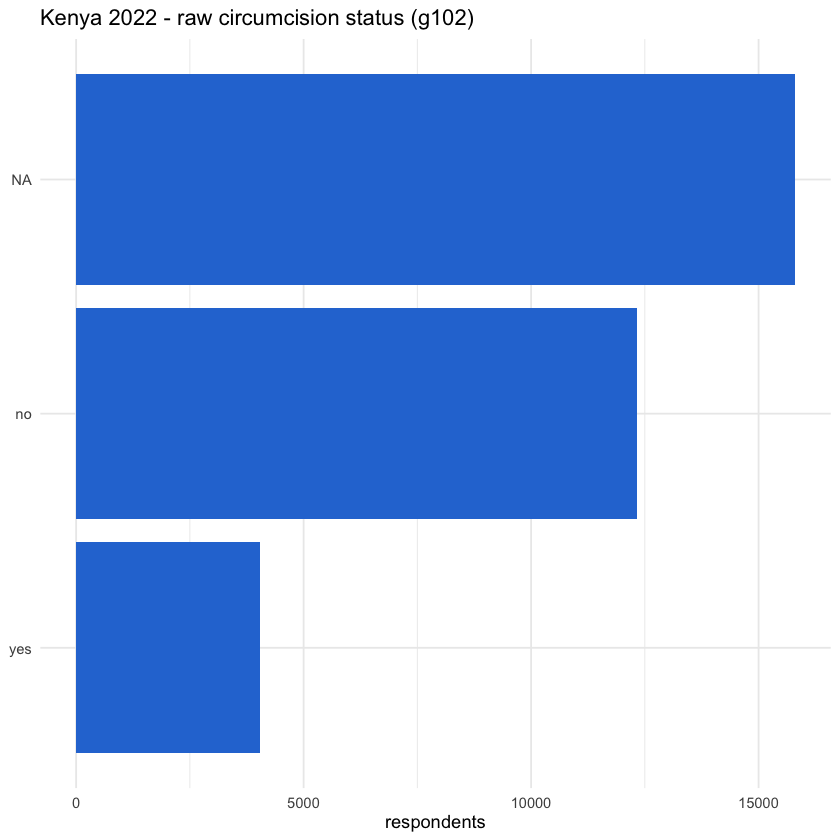

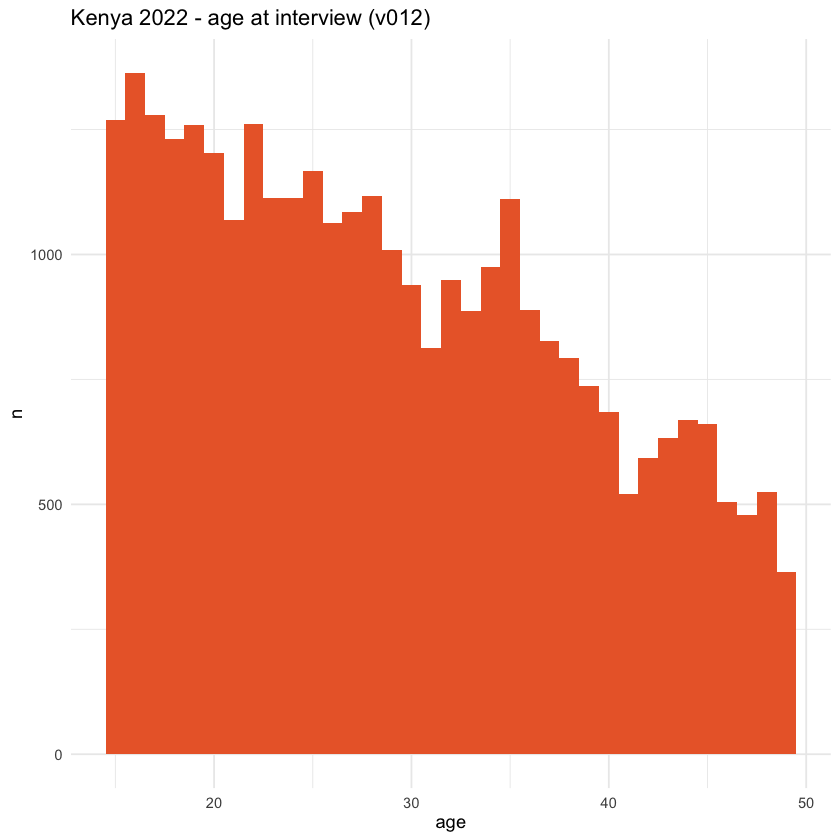

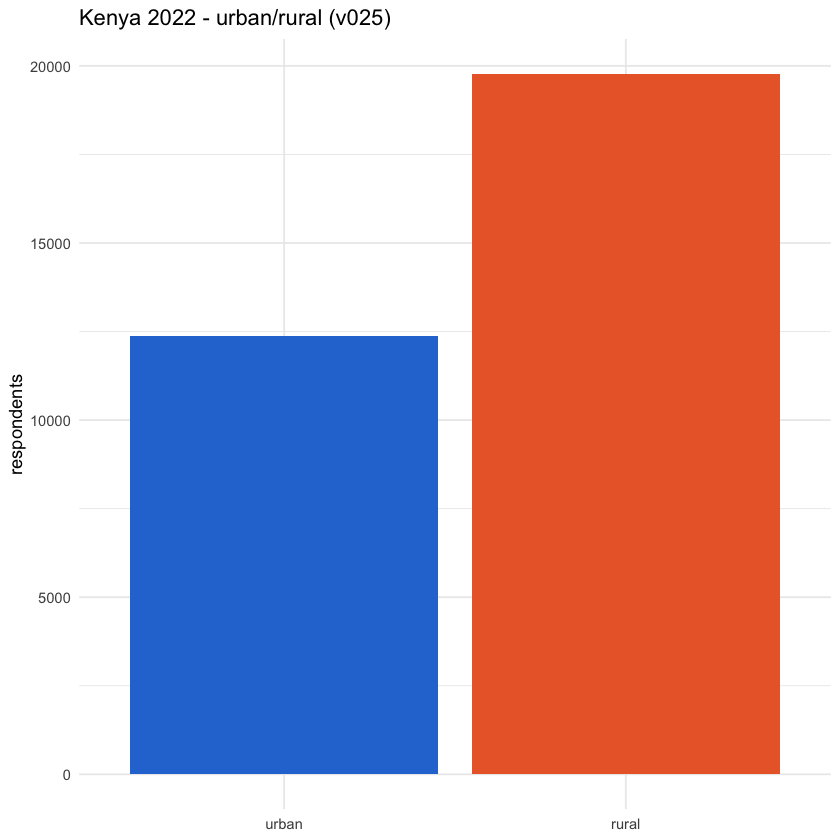

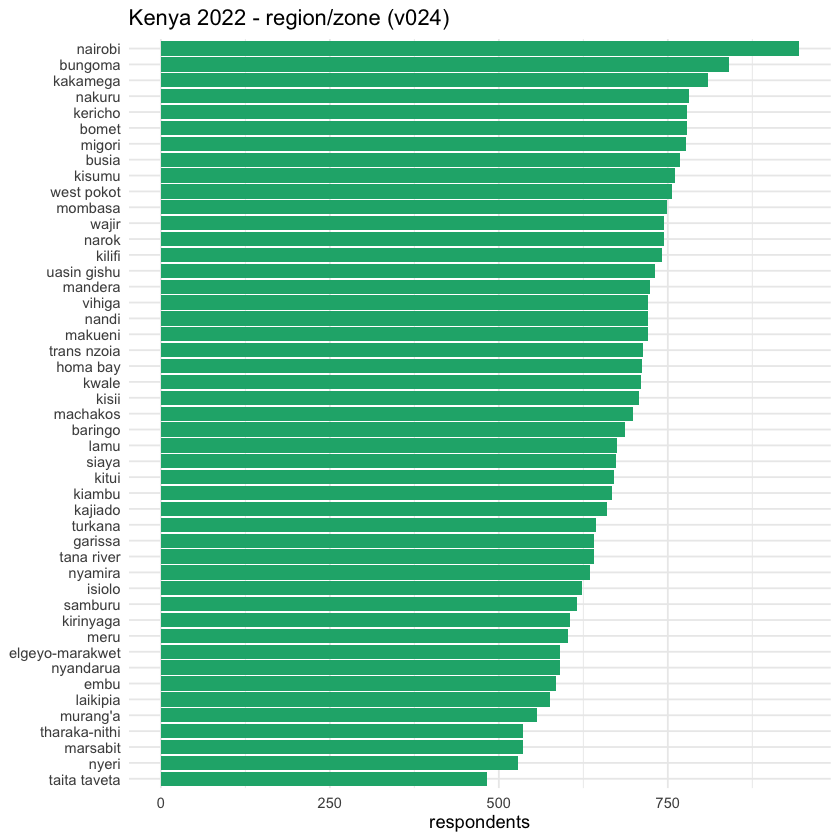

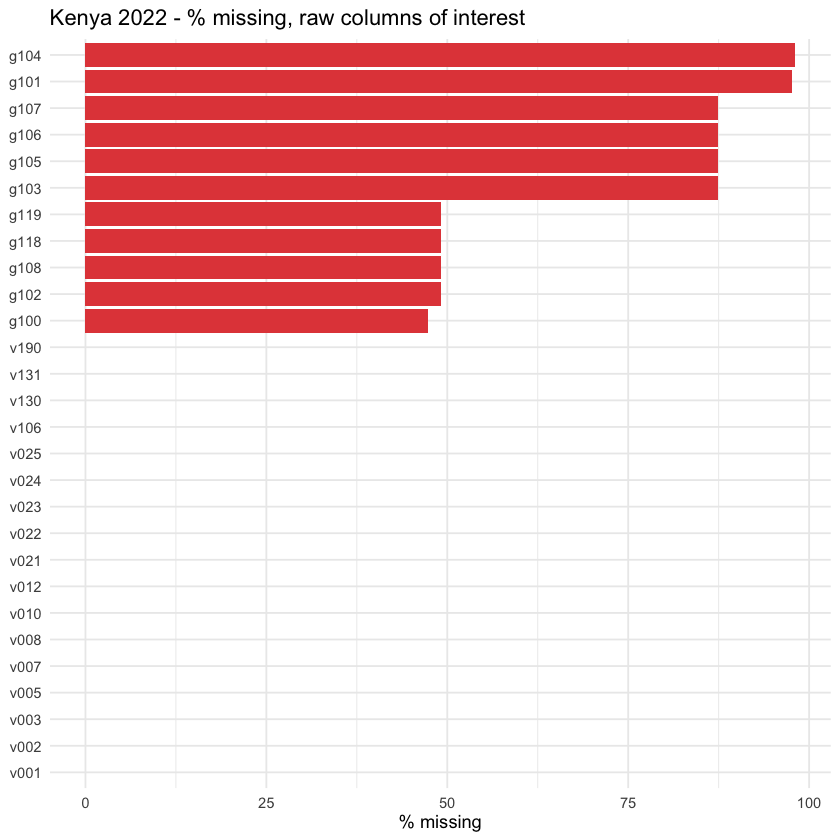

In [15]:
plot_raw_year <- function(raw, year) {
  p_status <- raw |>
    mutate(g102_label = as_factor(g102)) |>
    count(g102_label) |>
    ggplot(aes(x = fct_reorder(g102_label, n), y = n)) +
    geom_col(fill = "#2a78d6") +
    coord_flip() +
    labs(title = paste(country_name, year, "- raw circumcision status (g102)"),
         x = NULL, y = "respondents")

  p_age <- ggplot(raw, aes(x = v012)) +
    geom_histogram(binwidth = 1, fill = "#eb6834") +
    labs(title = paste(country_name, year, "- age at interview (v012)"), x = "age", y = "n")

  p_urban <- raw |>
    mutate(v025_label = as_factor(v025)) |>
    count(v025_label) |>
    ggplot(aes(x = v025_label, y = n, fill = v025_label)) +
    geom_col() +
    scale_fill_manual(values = year_palette[1:2], guide = "none") +
    labs(title = paste(country_name, year, "- urban/rural (v025)"), x = NULL, y = "respondents")

  p_region <- raw |>
    mutate(v024_label = as_factor(v024)) |>
    count(v024_label) |>
    ggplot(aes(x = fct_reorder(v024_label, n), y = n)) +
    geom_col(fill = "#1baf7a") +
    coord_flip() +
    labs(title = paste(country_name, year, "- region/zone (v024)"), x = NULL, y = "respondents")

  present <- intersect(raw_vars_of_interest, names(raw))
  missingness <- tibble(
    variable = present,
    pct_missing = vapply(present, function(v) round(100 * mean(is.na(raw[[v]])), 1), numeric(1))
  ) |> arrange(desc(pct_missing))

  p_missing <- ggplot(missingness, aes(x = fct_reorder(variable, pct_missing), y = pct_missing)) +
    geom_col(fill = "#e34948") +
    coord_flip() +
    labs(title = paste(country_name, year, "- % missing, raw columns of interest"),
         x = NULL, y = "% missing")

  print(p_status); print(p_age); print(p_urban); print(p_region); print(p_missing)
}

for (yr in names(raw_by_year)) {
  plot_raw_year(raw_by_year[[yr]], yr)
}

# Circumcision status (raw g102)

In [16]:
plot_raw_status <- function(raw, year) {

  raw |>
    mutate(
      g102_label = as_factor(g102),
      g102_label = fct_explicit_na(g102_label, na_level = "Missing")
    ) |>
    count(g102_label) |>
    mutate(
      percent = n / sum(n) * 100, label = paste0(format(n, big.mark = ","),
        " (", sprintf("%.1f", percent), "%)"
      )
    ) |>
    ggplot(aes( x = fct_reorder(g102_label, n), y = n, fill = g102_label
    )) +

    # Bars
    geom_col(width = 0.65,
      show.legend = FALSE
    ) +

    # Labels at the end of each bar
    geom_text(aes(label = label),
      hjust = -0.05,
      size = 4.5
    ) +

    coord_flip() +

    # Consistent colours
    scale_fill_manual(
      values = c(
        "YES" = "#D55E00",
        "NO" = "#0072B2",
        "Missing" = "#999999"
      )
    ) +

    # Format x-axis numbers
    scale_y_continuous(
      labels = scales::comma,
      expand = expansion(mult = c(0, 0.30))
    ) +

    labs(
      title = paste(country_name, year),
      subtitle = "Raw circumcision status (DHS variable g102)",
      x = "Respondent Status",
      y = "Number of respondents"
    ) +

    theme_minimal(base_size = 16) +

    theme(
      # Center title and subtitle
      plot.title = element_text(face = "bold",size = 20,hjust = 0.5),

      plot.subtitle = element_text( face = "bold",size = 13,hjust = 0.5,margin = margin(b = 20)
      ),

      # Category labels
      axis.text.y = element_text(size = 13, face = "bold",),
      axis.title.y = element_text(size = 14,face = "bold",margin = margin(t = 10)),

      # X-axis
      axis.text.x = element_text(size = 12,face = "bold"),

      axis.title.x = element_text(size = 14,face = "bold",margin = margin(t = 10)),

      # Remove unnecessary gridlines
      panel.grid.major.y = element_blank(),
      panel.grid.minor = element_blank(),

      # Add some breathing room around plot
      plot.margin = margin( t = 15,r = 20, b = 15,l = 15
      )
    )
}

Warning message:
"There was 1 warning in `mutate()`.
i In argument: `g102_label = fct_explicit_na(g102_label, na_level =
  "Missing")`.
Caused by warning:
! `fct_explicit_na()` was deprecated in forcats 1.0.0.
i Please use `fct_na_value_to_level()` instead."


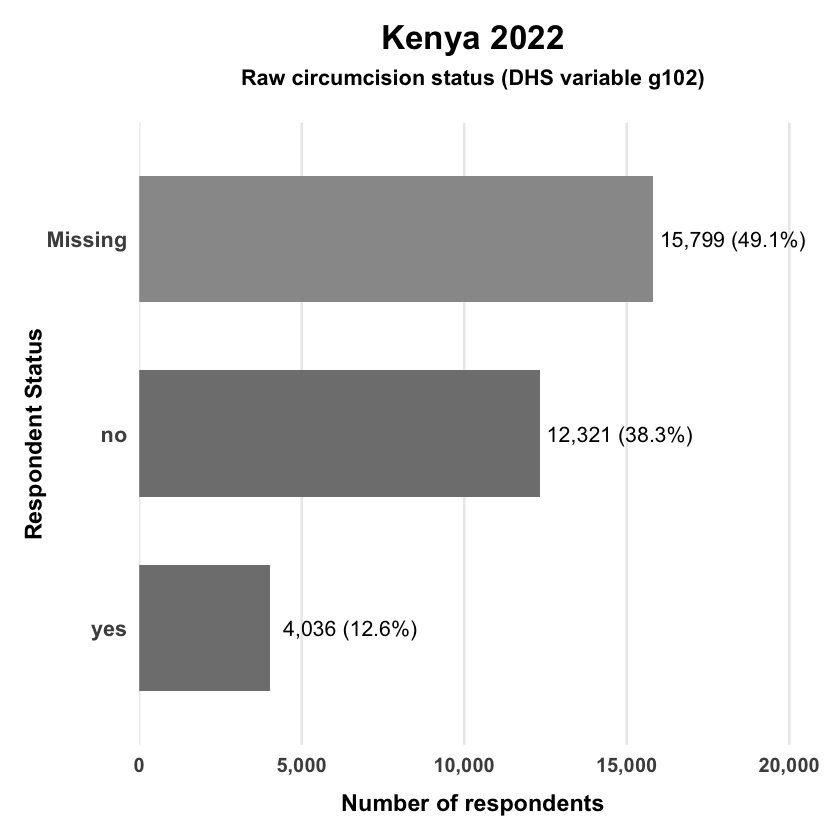

In [17]:
plot_raw_status(raw_by_year[[latest_year]], latest_year)

# Age at interview (v012)

In [18]:
plot_raw_age <- function(raw, year) {

  ggplot(raw, aes(x = v012)) +

    # Histogram
    geom_histogram(
      binwidth = 1,
      fill = "#0072B2",
      color = "white",
      linewidth = 0.2
    ) +

    # Titles and labels
    labs(
      title = paste(country_name, year),
      subtitle = "Age at interview (DHS variable v012)",
      x = "Age (years)",
      y = "Number of respondents"
    ) +

    # Cleaner x-axis
    scale_x_continuous(
      breaks = seq(
        floor(min(raw$v012, na.rm = TRUE)),
        ceiling(max(raw$v012, na.rm = TRUE)),
        by = 5
      ),
      expand = expansion(mult = c(0.01, 0.02))
    ) +

    # Cleaner y-axis
    scale_y_continuous(
      labels = scales::comma,
      expand = expansion(mult = c(0, 0.05))
    ) +

    theme_minimal(base_size = 16) +

    theme(
      # Center title
      plot.title = element_text(face = "bold", size = 20,hjust = 0.5
      ),

      # Center subtitle underneath
      plot.subtitle = element_text(size = 13, hjust = 0.5,margin = margin(b = 20)),

      # Axis text
      axis.text.x = element_text( size = 12,face = "bold"),

      axis.text.y = element_text(size = 12,face = "bold"),

      # Axis titles
      axis.title.x = element_text(size = 14,face = "bold",margin = margin(t = 10)),
      


      axis.title.y = element_text(size = 14,face = "bold", margin = margin(r = 10)),

      # Remove unnecessary gridlines
      panel.grid.minor = element_blank(),

      # Clean margins
      plot.margin = margin(
        t = 15,
        r = 20,
        b = 15,
        l = 20
      )
    )
}

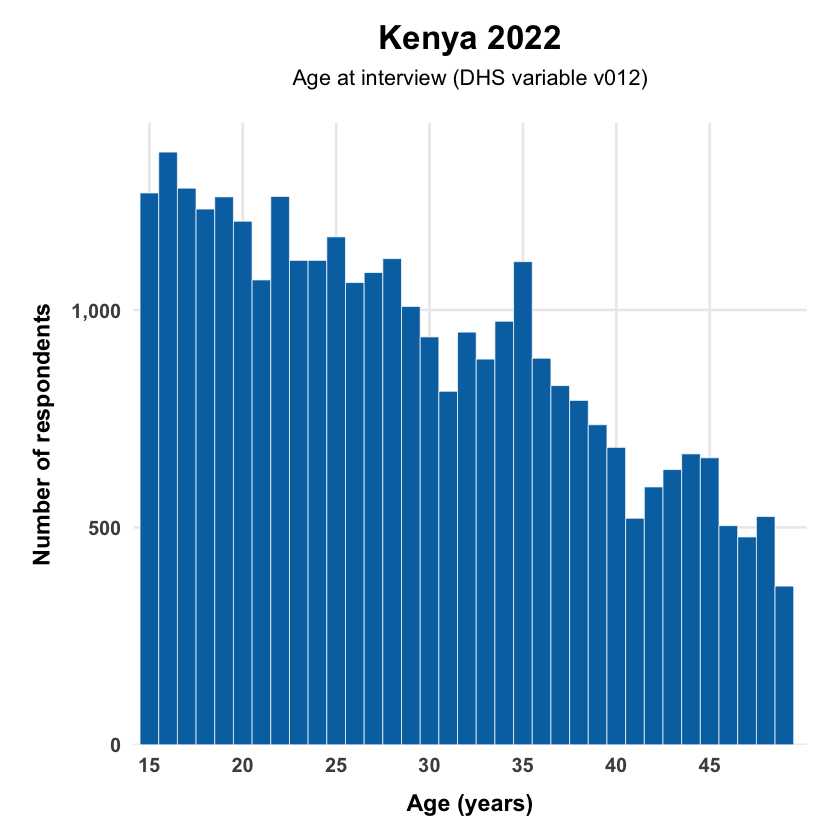

In [19]:
plot_raw_age(raw_by_year[[latest_year]], latest_year)

# Urban/rural (v025)

In [20]:
plot_raw_urban_rural <- function(raw, year) {

  raw |>
    mutate(
      v025_label = as_factor(v025)
    ) |>
    count(v025_label) |>
    mutate(
      percent = n / sum(n) * 100,
      label = paste0(
        format(n, big.mark = ","),
        " (", sprintf("%.1f", percent), "%)"
      )
    ) |>
    ggplot(
      aes(
        x = v025_label,
        y = n,
        fill = v025_label
      )
    ) +

    # Bars
    geom_col(
      width = 0.6,
      show.legend = FALSE
    ) +

    # Count + percentage labels
    geom_text(
      aes(label = label),
      vjust = -0.4,
      size = 4.5
    ) +

    # Consistent colours
    scale_fill_manual(
      values = year_palette[1:2],
      guide = "none"
    ) +

    # Labels
    labs(
      title = paste(country_name, year),
      subtitle = "Place of residence (DHS variable v025)",
      x = NULL,
      y = "Number of respondents"
    ) +

    # More space above bars for labels
    scale_y_continuous(
      labels = scales::comma,
      expand = expansion(mult = c(0, 0.18))
    ) +

    theme_minimal(base_size = 16) +

    theme(
      # Center title
      plot.title = element_text(face = "bold",size = 20,hjust = 0.5),

      # Center subtitle
      plot.subtitle = element_text(size = 13,hjust = 0.5,margin = margin(b = 20)),

      # Category labels
      axis.text.x = element_text(size = 13),

      axis.text.y = element_text(size = 12),

      # Y-axis title
      axis.title.y = element_text(size = 14, margin = margin(r = 10)),

      # Remove unnecessary gridlines
      panel.grid.major.x = element_blank(),
      panel.grid.minor = element_blank(),

      # Plot spacing
      plot.margin = margin(t = 15,r = 20,b = 15,l = 20
      )
    )
}

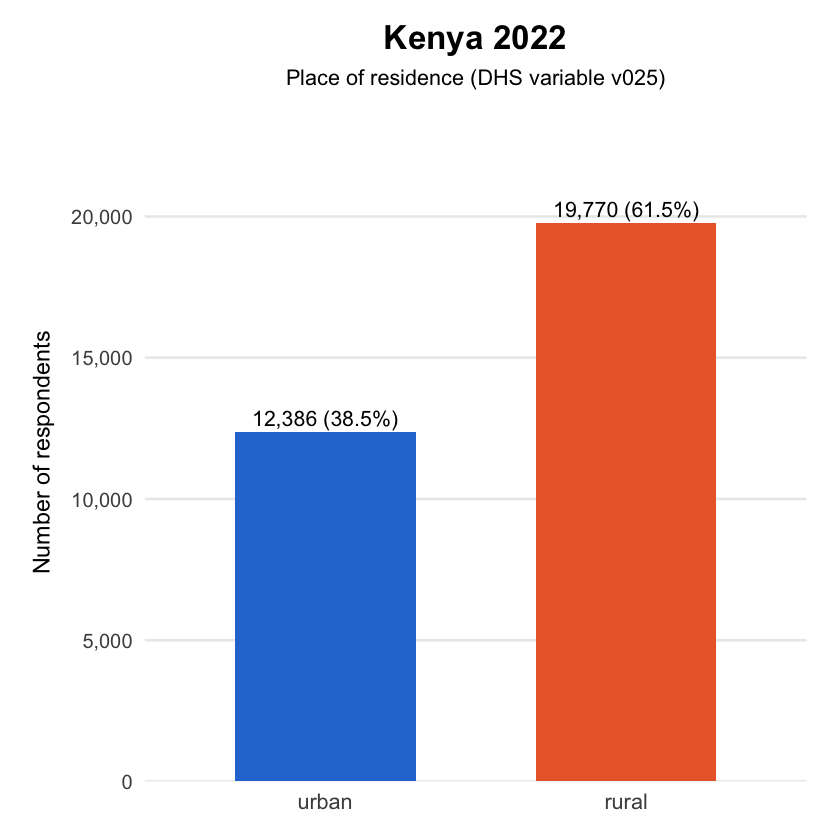

In [21]:
plot_raw_urban_rural(raw_by_year[[latest_year]], latest_year)

# Region/zone (v024):

In [22]:
plot_raw_region <- function(raw, year) {

  raw |>
    mutate(
      v024_label = as_factor(v024)
    ) |>
    count(v024_label) |>
    mutate(
      percent = n / sum(n) * 100,
      label = paste0(
        format(n, big.mark = ","),
        " (", sprintf("%.1f", percent), "%)"
      )
    ) |>
    ggplot(
      aes(
        x = fct_reorder(v024_label, n),
        y = n
      )
    ) +

    # Bars
    geom_col(
      fill = "#1baf7a",
      width = 0.65
    ) +

    # Count + percentage labels
    geom_text(
      aes(label = label),
      hjust = -0.05,
      size = 4
    ) +

    coord_flip() +

    # Labels
    labs(
      title = paste(country_name, year),
      subtitle = "Region/zone (DHS variable v024)",
      x = NULL,
      y = "Number of respondents"
    ) +

    # Give labels room on the right
    scale_y_continuous(
      labels = scales::comma,
      expand = expansion(mult = c(0, 0.25))
    ) +

    theme_minimal(base_size = 16) +

    theme(
      # Center title
      plot.title = element_text(
        face = "bold",
        size = 20,
        hjust = 0.5
      ),

      # Center subtitle
      plot.subtitle = element_text(
        size = 13,
        hjust = 0.5,
        margin = margin(b = 20)
      ),

      # Region names
      axis.text.y = element_text(
        size = 11
      ),

      # Number axis
      axis.text.x = element_text(
        size = 11
      ),

      axis.title.x = element_text(
        size = 14,
        margin = margin(t = 10)
      ),

      # Remove unnecessary gridlines
      panel.grid.major.y = element_blank(),
      panel.grid.minor = element_blank(),

      # Plot margins
      plot.margin = margin(
        t = 15,
        r = 30,
        b = 15,
        l = 15
      )
    )
}

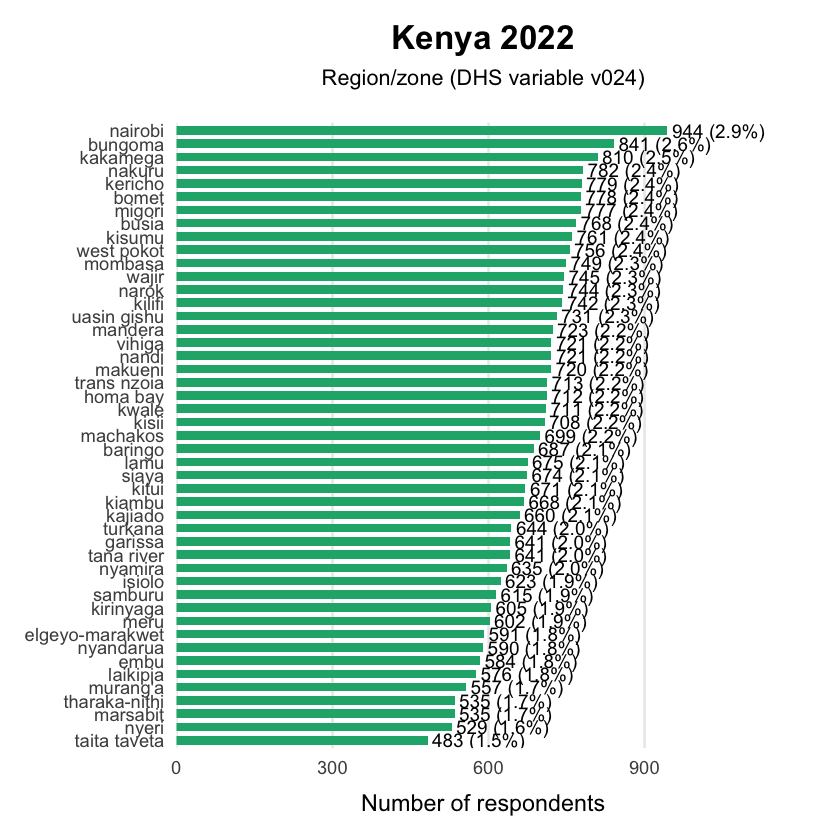

In [23]:
plot_raw_region(raw_by_year[[latest_year]], latest_year)

# % missing across columns of interest

In [24]:
plot_raw_missingness <- function(raw, vars = raw_vars_of_interest, year) {

  present <- intersect(vars, names(raw))

  missingness <- tibble(
    variable = present,
    pct_missing = vapply(
      present,
      function(v) round(100 * mean(is.na(raw[[v]])), 1),
      numeric(1)
    )
  ) |>
    arrange(desc(pct_missing))

  ggplot(
    missingness,
    aes(
      x = fct_reorder(variable, pct_missing),
      y = pct_missing
    )
  ) +

    # Bars
    geom_col(
      fill = "#D55E00",
      width = 0.65
    ) +

    # Percentage labels
    geom_text(
      aes(label = paste0(pct_missing, "%")),
      hjust = -0.05,
      size = 4
    ) +

    coord_flip() +

    # Labels
    labs(
      title = paste(country_name, year),
      subtitle = "Percentage of missing values in columns of interest",
      x = NULL,
      y = "Missing (%)"
    ) +

    # Keep the scale at 0–100% and leave space for labels
    scale_y_continuous(
      limits = c(0, 100),
      breaks = seq(0, 100, by = 20),
      expand = expansion(mult = c(0, 0.08))
    ) +

    theme_minimal(base_size = 16) +

    theme(
      # Center title
      plot.title = element_text(
        face = "bold",
        size = 20,
        hjust = 0.5
      ),

      # Center subtitle
      plot.subtitle = element_text(
        size = 13,
        hjust = 0.5,
        margin = margin(b = 20)
      ),

      # Variable names
      axis.text.y = element_text(
        size = 11
      ),

      # Percentage axis
      axis.text.x = element_text(
        size = 11
      ),

      axis.title.x = element_text(
        size = 14,
        margin = margin(t = 10)
      ),

      # Remove unnecessary gridlines
      panel.grid.major.y = element_blank(),
      panel.grid.minor = element_blank(),

      # Margins
      plot.margin = margin(
        t = 15,
        r = 25,
        b = 15,
        l = 15
      )
    )
}

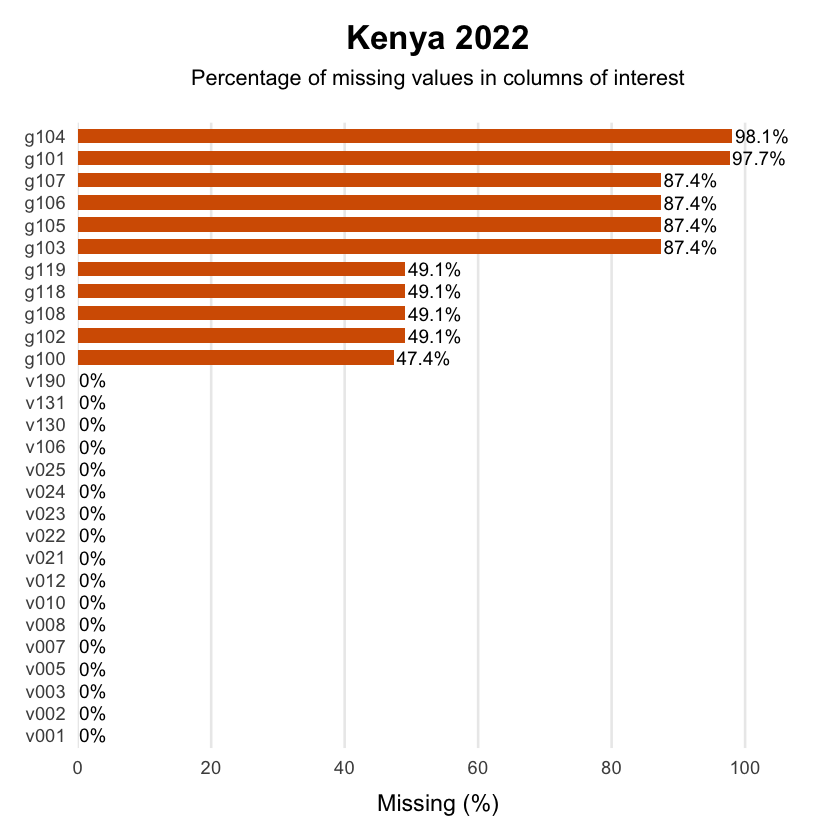

In [25]:
plot_raw_missingness(raw_by_year[[latest_year]], year = latest_year)

## 6. Load the admin-1 boundary data and map it

The supplied Kenya geography file contains 13 DHS admin-1 polygons. It does not contain
cluster IDs or released GPS coordinates. The notebook therefore keeps the polygon
geometry, displays its metadata, and joins respondents to regions through `v024` and
`REGCODE`. It does not present polygon boundaries as cluster locations.

,REGCODE,DHSREGEN,REGNAME,LEVELCO
,<dbl>,<chr>,<chr>,<chr>
1,30,Baringo,Baringo,Admin1
2,36,Bomet,Bomet,Admin1
3,39,Bungoma,Bungoma,Admin1
4,40,Busia,Busia,Admin1
5,28,Elgeyo-Marakwet,Elgeyo-Marakwet,Admin1


===== 2022 - admin-1 boundary geography =====
columns: ISO, FIPS, DHSCC, SVYTYPE, SVYYEAR, CNTRYNAMEE, CNTRYNAMEF, CNTRYNAMES, DHSREGEN, DHSREGFR, DHSREGSP, SVYID, REG_ID, Svy_Map, MULTLEVEL, LEVELRNK, REGVAR, REGCODE, REGNAME, OTHREGVAR, OTHREGCO, OTHREGNA, LEVELCO, LEVELNA, REPALLIND, REGNOTES, SVYNOTES, geometry 
counties: 47 


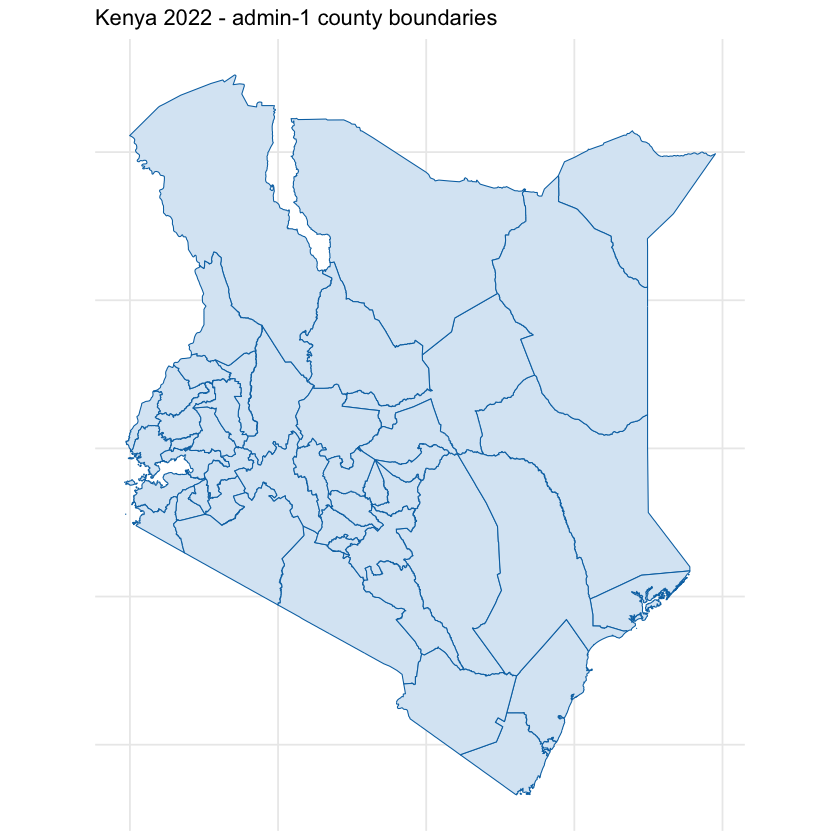

In [26]:
# The Kenya spatial package is an admin-1 polygon layer, not a DHS
# cluster-coordinate file. Inspect the boundary schema without treating
# polygons as cluster locations.
geo_raw_by_year <- list()

for (i in seq_len(nrow(survey_years))) {
  yr <- survey_years$year[i]
  if (is.na(survey_years$shp_path[i])) {
    warning("Year ", yr, " has no admin-1 boundary .shp, skipping.")
    next
  }

  geo_raw <- st_read(survey_years$shp_path[i], quiet = TRUE)
  geo_raw_by_year[[as.character(yr)]] <- geo_raw

  cat("=====", yr, "- admin-1 boundary geography =====\n")
  cat("columns:", paste(names(geo_raw), collapse = ", "), "\n")
  cat("counties:", nrow(geo_raw), "\n")
  IRdisplay::display(as.data.frame(head(
    st_drop_geometry(geo_raw)[, c("REGCODE", "DHSREGEN", "REGNAME", "LEVELCO")], 5
  )))
  print(
    ggplot(geo_raw) +
      geom_sf(fill = "#d9e8f5", color = "#0072B2", linewidth = 0.3) +
      labs(title = paste(country_name, yr, "- admin-1 county boundaries")) +
      theme(axis.text = element_blank(), axis.title = element_blank())
  )
}

,REGCODE,REGNAME,LEVELCO,LEVELNA
,<dbl>,<chr>,<chr>,<chr>
1,30,Baringo,Admin1,Counties
2,36,Bomet,Admin1,Counties
3,39,Bungoma,Admin1,Counties
4,40,Busia,Admin1,Counties
5,28,Elgeyo-Marakwet,Admin1,Counties



Kenya - 2022 admin-1 boundaries
regions: 47 
boundary level: Admin1 
survey alignment variable: hv024 



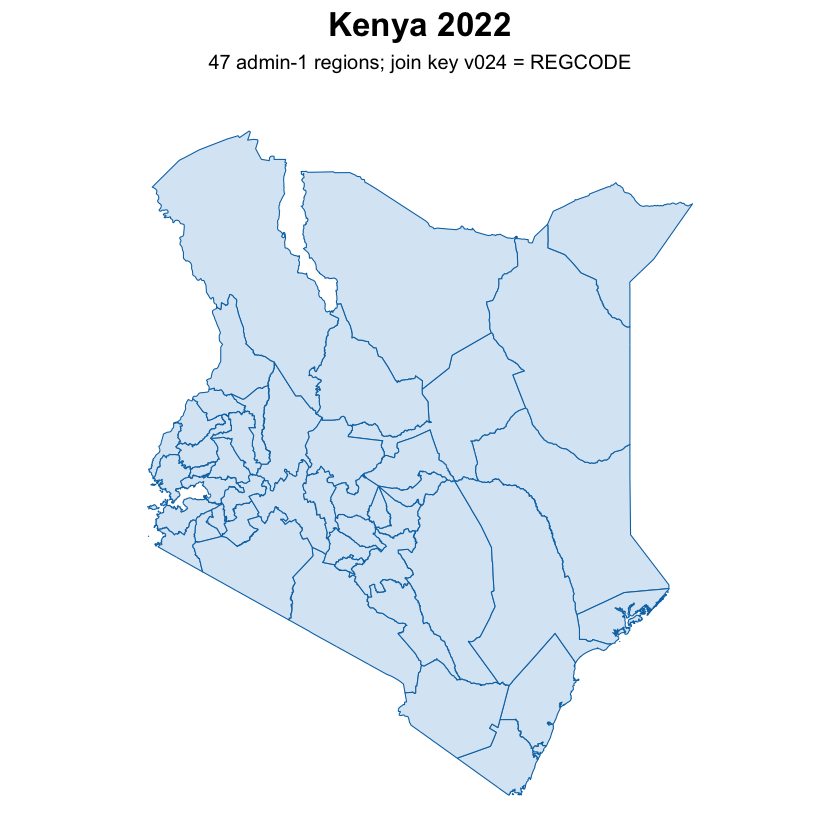

In [27]:
geo_raw_by_year <- list()

for (i in seq_len(nrow(survey_years))) {
  yr <- survey_years$year[i]
  if (is.na(survey_years$shp_path[i])) {
    warning("Year ", yr, " has no admin-1 boundary .shp, skipping.")
    next
  }

  geo_raw <- st_read(survey_years$shp_path[i], quiet = TRUE)
  geo_raw_by_year[[as.character(yr)]] <- geo_raw

  cat("\n====================================\n")
  cat(country_name, "-", yr, "admin-1 boundaries\n")
  cat("====================================\n")
  cat("regions:", nrow(geo_raw), "\n")
  cat("boundary level:", paste(unique(geo_raw$LEVELCO), collapse = ", "), "\n")
  cat("survey alignment variable:", paste(unique(geo_raw$REGVAR), collapse = ", "), "\n\n")

  display_data <- geo_raw |>
    st_drop_geometry() |>
    select(REGCODE, REGNAME, LEVELCO, LEVELNA) |>
    head(5)
  IRdisplay::display(as.data.frame(display_data))

  p_map <- ggplot(geo_raw) +
    geom_sf(fill = "#d9e8f5", color = "#0072B2", linewidth = 0.3) +
    labs(
      title = paste(country_name, yr),
      subtitle = paste(nrow(geo_raw), "admin-1 regions; join key v024 = REGCODE")
    ) +
    theme_minimal(base_size = 14) +
    theme(
      plot.title = element_text(face = "bold", size = 20, hjust = 0.5),
      plot.subtitle = element_text(size = 12, hjust = 0.5, margin = margin(b = 15)),
      panel.grid = element_blank(),
      axis.text = element_blank(),
      axis.title = element_blank()
    )
  print(p_map)
}

## 7. Harmonize into a common schema

The survey and boundary schemas are normalized here. For Kenya, `v024` is retained
as `region_code_survey`, and the admin-1 boundary's `REGCODE`/`REGNAME` become the
geographic region fields. GPS columns remain explicitly unavailable because the supplied
file is polygon geography.

In [28]:
standardize_region <- function(x) {
  x |> as.character() |> toupper() |> str_replace_all("[^A-Z ]", " ") |> str_squish()
}

load_person_level <- function(raw, year) {
  has_col <- function(v) v %in% names(raw)

  person <- raw |>
    transmute(
      survey_year = year,
      survey_type = "DHS",
      resp_id = paste(year, v001, v002, v003, sep = "-"),
      cluster = v001,
      household = v002,
      line = v003,
      weight = v005 / 1e6,
      psu = v021,
      strata = as.numeric(v022),
      region_code_survey = as.numeric(v024),
      region_zone_survey = standardize_region(as_factor(v024)),
      region_state_survey = if (has_col("sstate1")) standardize_region(as_factor(sstate1)) else NA_character_,
      urban_rural = as_factor(v025) |> as.character(),
      age = as.numeric(v012),
      birth_year = as.numeric(v010),
      interview_year = as.numeric(v007),
      fgm_heard = as_factor(g100) |> as.character(),
      fgm_status = case_when(
        as_factor(g102) == "yes" ~ 1L,
        as_factor(g102) == "no" ~ 0L,
        as_factor(g100) == "no" & as_factor(g101) == "no" ~ 0L,
        TRUE ~ NA_integer_
      ),
      fgm_age_raw = as.numeric(g106),
      fgm_age = if_else(fgm_age_raw %in% 0:49, fgm_age_raw, NA_real_),
      fgm_type = case_when(
        as_factor(g103) == "yes" ~ "flesh removed",
        as_factor(g104) == "yes" ~ "nicked, no flesh removed",
        as_factor(g105) == "yes" ~ "sewn closed",
        fgm_status == 1 ~ "type not specified",
        TRUE ~ NA_character_
      ),
      n_daughters_circumcised = suppressWarnings(as.numeric(g108)),
      education = if (has_col("v106")) as_factor(v106) |> as.character() else NA_character_,
      wealth = if (has_col("v190")) as_factor(v190) |> as.character() else NA_character_,
      religion = if (has_col("v130")) as_factor(v130) |> as.character() else NA_character_,
      ethnicity_raw = if (has_col("v131")) as_factor(v131) |> as.character() else NA_character_,
      attitude_continue = if (has_col("g119")) as_factor(g119) |> as.character() else NA_character_,
      supports_continuation = case_when(
        attitude_continue == "continued" ~ 1L,
        attitude_continue == "stopped" ~ 0L,
        TRUE ~ NA_integer_
      )
    )

  person |>
    mutate(
      fgm_event = fgm_status,
      time = if_else(fgm_event == 1, fgm_age, pmin(age, max_age_years)),
      birth_cohort = cut(
        birth_year,
        breaks = seq(1950, 2025, by = 5),
        right = FALSE,
        labels = paste0(seq(1950, 2020, by = 5), " to ", seq(1954, 2024, by = 5))
      )
    )
}

# Kenya's supplied DHS Spatial Data Repository file contains admin-1 polygons,
# not cluster points. REGCODE aligns to the survey's v024 codes (see REGVAR metadata).
load_cluster_geo <- function(shp_path) {
  geo <- st_read(shp_path, quiet = TRUE)
  required <- c("REGCODE", "REGNAME", "DHSREGEN", "LEVELCO")
  missing <- setdiff(required, names(geo))
  if (length(missing) > 0) stop("Boundary file is missing required fields: ", paste(missing, collapse = ", "))

  geo |>
    transmute(
      region_code_geo = as.numeric(REGCODE),
      region_state_geo = standardize_region(REGNAME),
      region_zone_geo = standardize_region(DHSREGEN),
      lat = NA_real_,
      lon = NA_real_,
      missing_gps = NA,
      geometry = geometry
    )
}

# Join admin-1 regions by the DHS survey's v024 code, not by cluster GPS.
attach_region <- function(person, geo) {
  person |>
    left_join(
      st_drop_geometry(geo) |> select(region_code_geo, region_state_geo, region_zone_geo),
      by = c("region_code_survey" = "region_code_geo")
    ) |>
    mutate(
      region = coalesce(region_state_geo, region_zone_survey),
      lat = NA_real_,
      lon = NA_real_,
      missing_gps = NA
    )
}

load_daughter_events <- function(raw, year) {
  gidx_cols <- names(raw)[str_detect(names(raw), "^gidx_[0-9]{2}$")]
  if (length(gidx_cols) == 0) return(tibble())

  roster <- raw |>
    mutate(
      resp_id = paste(year, v001, v002, v003, sep = "-"),
      across(matches("^g121_[0-9]{2}$"), ~ as_factor(.) |> as.character())
    ) |>
    select(resp_id, matches("^gidx_[0-9]{2}$"), matches("^g121_[0-9]{2}$"), matches("^g122_[0-9]{2}$")) |>
    pivot_longer(
      -resp_id,
      names_to = c(".value", "slot"),
      names_pattern = "^(gidx|g121|g122)_([0-9]{2})$"
    ) |>
    filter(!is.na(gidx)) |>
    transmute(
      resp_id,
      birth_order = as.integer(gidx),
      daughter_status = case_when(g121 == "yes" ~ 1L, g121 == "no" ~ 0L, TRUE ~ NA_integer_),
      daughter_age_at_fgm_raw = as.numeric(g122)
    )

  ages <- raw |>
    mutate(resp_id = paste(year, v001, v002, v003, sep = "-")) |>
    select(resp_id, matches("^bidx_[0-9]{2}$"), matches("^b8_[0-9]{2}$")) |>
    pivot_longer(
      -resp_id,
      names_to = c(".value", "slot"),
      names_pattern = "^(bidx|b8)_([0-9]{2})$"
    ) |>
    filter(!is.na(bidx)) |>
    transmute(resp_id, birth_order = as.integer(bidx), daughter_current_age = as.numeric(b8))

  roster |>
    left_join(ages, by = c("resp_id", "birth_order")) |>
    filter(!is.na(daughter_status)) |>
    mutate(
      daughter_age_at_fgm = if_else(daughter_age_at_fgm_raw %in% 0:19, daughter_age_at_fgm_raw, NA_real_),
      fgm_event = daughter_status,
      time = if_else(fgm_event == 1, daughter_age_at_fgm, pmin(daughter_current_age, max_age_years)),
      birth_year = year - daughter_current_age,
      birth_cohort = cut(
        birth_year,
        breaks = seq(1950, 2025, by = 5),
        right = FALSE,
        labels = paste0(seq(1950, 2020, by = 5), " to ", seq(1954, 2024, by = 5))
      )
    ) |>
    transmute(resp_id, survey_year = year, birth_order, age = daughter_current_age,
              birth_year, birth_cohort, fgm_event, time)
}

## 8. Data quality report

Surfaces the things worth knowing before trusting a year's data: how much is missing and
whether it's structural (skip pattern, e.g. `g102` is only asked when `g100 == yes`) or
a true gap, implausible ages at cutting, duplicate respondent ids, clusters with no GPS
released, and whether the survey file's own state labels agree with the geography
file's `ADM1NAME` for the same cluster.

In [29]:
qa_report <- function(person, geo, year) {
  n <- nrow(person)
  pct_na <- function(x) round(100 * mean(is.na(x)), 1)

  missing_tbl <- tibble(
    variable = c("age", "region (admin-1 boundary)", "urban_rural", "weight",
                 "fgm_status", "fgm_age (among circumcised)"),
    pct_missing = c(
      pct_na(person$age), pct_na(person$region), pct_na(person$urban_rural),
      pct_na(person$weight), pct_na(person$fgm_status),
      round(100 * mean(is.na(person$fgm_age[person$fgm_status == 1])), 1)
    )
  )

  fgm_status_na <- is.na(person$fgm_status)
  structural_na <- sum(fgm_status_na & person$fgm_heard == "no", na.rm = TRUE)
  heard_na <- sum(fgm_status_na & is.na(person$fgm_heard))
  nonresponse_na <- sum(fgm_status_na & !is.na(person$fgm_heard) & person$fgm_heard != "no")

  implausible_age <- person |>
    filter(fgm_status == 1) |>
    summarise(
      age_gt_current = sum(fgm_age > age, na.rm = TRUE),
      age_missing = sum(is.na(fgm_age)),
      .groups = "drop"
    )

  dup_ids <- person |> count(resp_id) |> filter(n > 1) |> nrow()
  unmatched_region <- sum(is.na(person$region_state_geo))
  n_region_mismatch <- sum(
    person$region_code_survey != person$region_code_survey[match(person$region_state_geo, person$region_state_geo)],
    na.rm = TRUE
  )

  cat("=====", year, "=====\n")
  cat("respondents:", n, "  admin-1 regions:", nrow(geo), "\n\n")
  cat("-- missingness --\n"); print(missing_tbl)
  cat("\nfgm_status missing, structural (not asked, g100 == no):", structural_na, "\n")
  cat("fgm_status missing, g100 itself missing:", heard_na, "\n")
  cat("fgm_status missing, true item nonresponse:", nonresponse_na, "\n")
  cat("\ncircumcised respondents with fgm_age > current age:", implausible_age$age_gt_current, "\n")
  cat("circumcised respondents with fgm_age missing:", implausible_age$age_missing, "\n")
  cat("\nduplicate respondent ids:", dup_ids, "\n")
  cat("respondents with no admin-1 boundary match:", unmatched_region, "\n")
  cat("cluster GPS: not supplied by this admin-1 boundary file; point maps are not available.\n\n")

  invisible(list(missing_tbl = missing_tbl, dup_ids = dup_ids, unmatched_region = unmatched_region,
                 n_region_mismatch = n_region_mismatch))
}

## 9. Harmonize, preview it, describe it, and run the QA report

Reuses the raw files already read into `raw_by_year` in section 4, so nothing is read
from disk twice. Each year available is harmonized, shown as its first 5 rows with every
column visible, summarized column by column with `skimr::skim()`, then run through the
QA report. The daughters' roster is reconstructed here too, inheriting the design
variables (weight, cluster, region, urban/rural) from each daughter's mother, since a
daughter has none of her own.

In [30]:
person_by_year <- list()
geo_by_year <- list()
daughter_by_year <- list()

for (i in seq_len(nrow(survey_years))) {
  yr <- survey_years$year[i]
  if (is.null(raw_by_year[[as.character(yr)]]) || is.na(survey_years$shp_path[i])) {
    warning("Year ", yr, " is missing a Survey .dta or an admin-1 boundary .shp, skipping.")
    next
  }

  raw <- raw_by_year[[as.character(yr)]]
  person <- load_person_level(raw, yr)
  geo <- load_cluster_geo(survey_years$shp_path[i])
  person <- attach_region(person, geo)

  cat("=====", yr, "- harmonized, first 5 rows, every column visible =====\n")
  IRdisplay::display(as.data.frame(head(person, 5)))
  cat("\n=====", yr, "- column by column description =====\n")
  print(skim(person))
  cat("\n")

  qa_report(person, geo, yr)

  daughters <- load_daughter_events(raw, yr) |>
    left_join(
      person |> select(resp_id, survey_type, cluster, psu, strata, urban_rural,
                       region, weight, ethnicity_raw, lat, lon, missing_gps),
      by = "resp_id"
    )
  cat("=====", yr, "- daughters' roster reconstructed:", nrow(daughters),
      "daughters with a known circumcision status =====\n\n")

  person_by_year[[as.character(yr)]] <- person
  geo_by_year[[as.character(yr)]] <- geo
  daughter_by_year[[as.character(yr)]] <- daughters
}

survey_year,survey_type,resp_id,cluster,household,line,weight,psu,strata,region_code_survey,region_zone_survey,region_state_survey,urban_rural,age,birth_year,interview_year,fgm_heard,fgm_status,fgm_age_raw,fgm_age,fgm_type,n_daughters_circumcised,education,wealth,religion,ethnicity_raw,attitude_continue,supports_continuation,fgm_event,time,birth_cohort,region_state_geo,region_zone_geo,region,lat,lon,missing_gps
<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>
2022,DHS,2022-1-4-2,1,4,2,1.296049,1,1,1,MOMBASA,NA,urban,34,1987,2022,yes,1,9,9,flesh removed,0,no education,richer,islam,somali,stopped,0,1,9,1985 to 1989,MOMBASA,MOMBASA,MOMBASA,NA,NA,NA
2022,DHS,2022-1-7-2,1,7,2,1.296049,1,1,1,MOMBASA,NA,urban,38,1983,2022,NA,NA,NA,NA,NA,NA,secondary,richest,catholic,kamba,NA,NA,NA,NA,1980 to 1984,MOMBASA,MOMBASA,MOMBASA,NA,NA,NA
2022,DHS,2022-1-10-1,1,10,1,1.296049,1,1,1,MOMBASA,NA,urban,33,1989,2022,yes,0,NA,NA,NA,0,primary,richest,catholic,kikuyu,stopped,0,0,33,1985 to 1989,MOMBASA,MOMBASA,MOMBASA,NA,NA,NA
2022,DHS,2022-1-13-2,1,13,2,1.296049,1,1,1,MOMBASA,NA,urban,39,1982,2022,yes,0,NA,NA,NA,0,secondary,richest,catholic,kamba,stopped,0,0,39,1980 to 1984,MOMBASA,MOMBASA,MOMBASA,NA,NA,NA
2022,DHS,2022-1-20-2,1,20,2,1.296049,1,1,1,MOMBASA,NA,urban,30,1992,2022,yes,0,NA,NA,NA,0,primary,richer,other,mijikenda/swahili,stopped,0,0,30,1990 to 1994,MOMBASA,MOMBASA,MOMBASA,NA,NA,NA


===== 2022 - harmonized, first 5 rows, every column visible =====

===== 2022 - column by column description =====
-- Data Summary ------------------------
                           Values
Name                       person
Number of rows             32156 
Number of columns          37    
_______________________          
Column type frequency:           
  character                15    
  factor                   1     
  logical                  1     
  numeric                  20    
________________________         
Group variables            None  

-- Variable type: character ----------------------------------------------------
   skim_variable       n_missing complete_rate min max empty n_unique whitespace
 1 survey_type                 0         1       3   3     0        1          0
 2 resp_id                     0         1      10  16     0    32156          0
 3 region_zone_survey          0         1       4  15     0       47          0
 4 region_state_survey     321

## 10. Visuals and processed output

Weighted national/regional prevalence uses `survey::svydesign` on the DHS sample
design variables (`psu`, `strata`, `weight`), consistent with the design-based approach
in `FGM_Risk_Incidence.ipynb`. The cluster map is unweighted at the cluster level (small
clusters are noisy) and drops clusters with no released GPS, reporting how many were
dropped.

In [31]:
# plot_year <- function(person, geo, year) {
#   complete <- person |> filter(!is.na(fgm_status), !is.na(region))
#   des <- svydesign(ids = ~psu, strata = ~strata, weights = ~weight, data = complete, nest = TRUE)

#   prev_by_state <- svyby(~fgm_status, ~region, des, svymean) |>
#     as_tibble() |>
#     arrange(desc(fgm_status))

#   p_state <- ggplot(prev_by_state, aes(x = reorder(region, fgm_status), y = fgm_status)) +
#     geom_col(fill = "#4C6EF5") +
#     geom_errorbar(aes(ymin = pmax(fgm_status - 1.96 * se, 0), ymax = fgm_status + 1.96 * se),
#                   width = 0.2) +
#     coord_flip() +
#     labs(title = paste(country_name, year, "- weighted FGM prevalence by state"),
#          x = NULL, y = "prevalence") +
#     scale_y_continuous(labels = scales::percent)

#   p_age <- person |>
#     filter(fgm_status == 1, !is.na(fgm_age)) |>
#     ggplot(aes(x = fgm_age)) +
#     geom_histogram(binwidth = 1, fill = "#F76707") +
#     labs(title = paste(country_name, year, "- age at cutting"), x = "age", y = "n")

#   cluster_prev <- person |>
#     group_by(cluster) |>
#     summarise(n = n(), prev = mean(fgm_status, na.rm = TRUE), .groups = "drop")

#   map_pts <- geo |>
#     filter(!missing_gps) |>
#     inner_join(cluster_prev, by = "cluster")

#   p_map <- ggplot(map_pts) +
#     geom_sf(aes(color = prev, size = n), alpha = 0.8) +
#     scale_color_viridis_c(labels = scales::percent, name = "prevalence") +
#     labs(title = paste(country_name, year, "- cluster level prevalence"),
#          subtitle = paste(sum(geo$missing_gps), "of", nrow(geo), "clusters excluded, no GPS")) +
#     theme(axis.text = element_blank())

#   print(p_state); print(p_age); print(p_map)
#   invisible(list(prev_by_state = prev_by_state))
# }

# for (yr in names(person_by_year)) {
#   plot_year(person_by_year[[yr]], geo_by_year[[yr]], yr)
# }

# Weighted FGM prevalence by state

In [32]:
plot_state_prevalence <- function(person, year) {

  complete <- person |>
    filter(
      !is.na(fgm_status),
      !is.na(region),
      !is.na(psu),
      !is.na(strata),
      !is.na(weight)
    )

  des <- svydesign(
    ids = ~psu,
    strata = ~strata,
    weights = ~weight,
    data = complete,
    nest = TRUE
  )

  prev_by_state <- svyby(
    ~fgm_status,
    ~region,
    des,
    svymean,
    vartype = "se",
    na.rm = TRUE
  ) |>
    as_tibble() |>
    mutate(
      lower = pmax(fgm_status - 1.96 * se, 0),
      upper = pmin(fgm_status + 1.96 * se, 1),
      label = scales::percent(fgm_status, accuracy = 0.1)
    ) |>
    arrange(fgm_status)

  ggplot(
    prev_by_state,
    aes(x = reorder(region, fgm_status), y = fgm_status)
  ) +

    geom_col(
      fill = "#4C6EF5",
      width = 0.65
    ) +

    geom_errorbar(
      aes(ymin = lower, ymax = upper),
      width = 0.20,
      linewidth = 0.7
    ) +

    geom_text(
      aes(label = label),
      hjust = -0.15,
      size = 4
    ) +

    coord_flip() +

    scale_y_continuous(
      labels = scales::percent,
      limits = c(0, 1),
      breaks = seq(0, 1, by = 0.2),
      expand = expansion(mult = c(0, 0.12))
    ) +

    labs(
      title = paste(country_name, year),
      subtitle = "Weighted FGM prevalence by state with 95% confidence intervals",
      x = NULL,
      y = "FGM prevalence"
    ) +

    theme_minimal(base_size = 16) +

    theme(
      plot.title = element_text(
        face = "bold",
        size = 20,
        hjust = 0.5
      ),
      plot.subtitle = element_text(
        size = 13,
        hjust = 0.5,
        margin = margin(b = 20)
      ),
      axis.text.y = element_text(size = 11),
      axis.text.x = element_text(size = 11),
      axis.title.x = element_text(
        size = 14,
        margin = margin(t = 10)
      ),
      panel.grid.major.y = element_blank(),
      panel.grid.minor = element_blank(),
      plot.margin = margin(15, 25, 15, 15)
    )
}

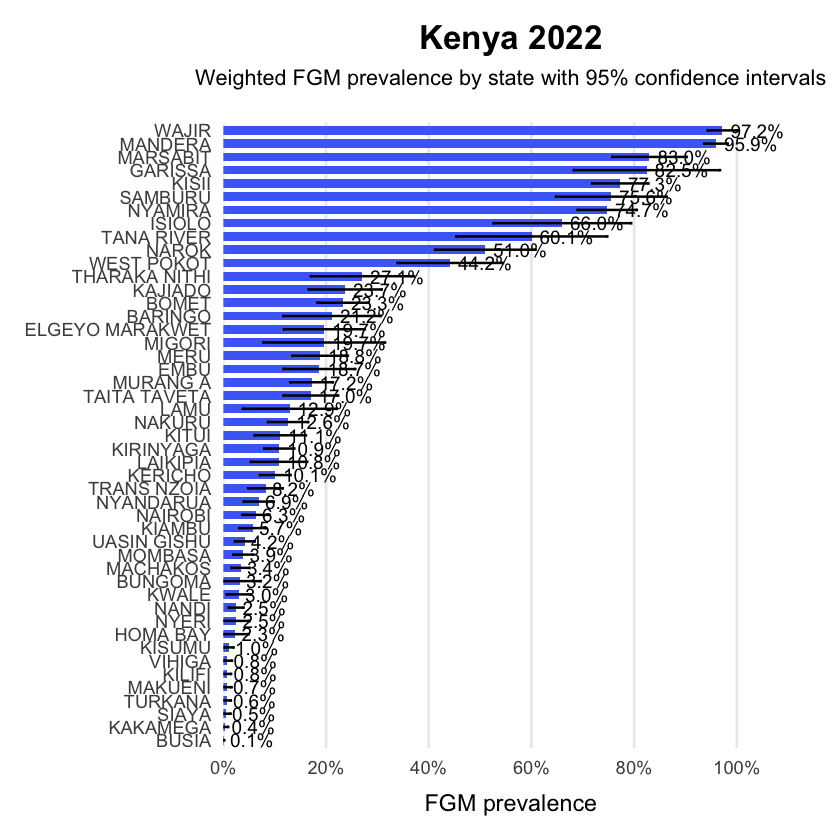

In [33]:
plot_state_prevalence(person_by_year[[latest_year]], latest_year)

# Age at cutting

In [34]:
plot_age_at_cutting <- function(person, year) {

  age_data <- person |>
    filter(
      fgm_status == 1,
      !is.na(fgm_age)
    )

  ggplot(
    age_data,
    aes(x = fgm_age)
  ) +

    geom_histogram(
      binwidth = 1,
      fill = "#F76707",
      color = "white",
      linewidth = 0.2
    ) +

    labs(
      title = paste(country_name, year),
      subtitle = "Age at cutting among women reporting FGM",
      x = "Age at cutting (years)",
      y = "Number of women"
    ) +

    scale_x_continuous(
      breaks = seq(
        floor(min(age_data$fgm_age, na.rm = TRUE)),
        ceiling(max(age_data$fgm_age, na.rm = TRUE)),
        by = 2
      ),
      expand = expansion(mult = c(0.01, 0.02))
    ) +

    scale_y_continuous(
      labels = scales::comma,
      expand = expansion(mult = c(0, 0.05))
    ) +

    theme_minimal(base_size = 16) +

    theme(
      plot.title = element_text(
        face = "bold",
        size = 20,
        hjust = 0.5
      ),
      plot.subtitle = element_text(
        size = 13,
        hjust = 0.5,
        margin = margin(b = 20)
      ),
      axis.text.x = element_text(size = 12),
      axis.text.y = element_text(size = 12),
      axis.title.x = element_text(
        size = 14,
        margin = margin(t = 10)
      ),
      axis.title.y = element_text(
        size = 14,
        margin = margin(r = 10)
      ),
      panel.grid.minor = element_blank(),
      plot.margin = margin(15, 20, 15, 20)
    )
}

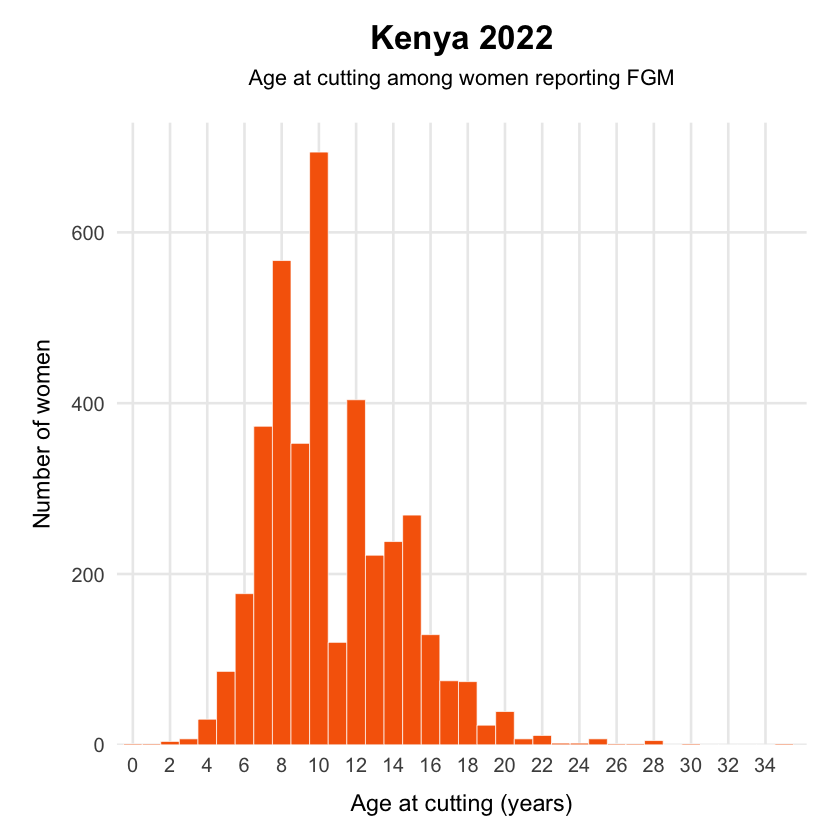

In [35]:
plot_age_at_cutting(person_by_year[[latest_year]], latest_year)

In [36]:
person_by_year[[latest_year]] |>
  filter(fgm_status == 1, !is.na(fgm_age)) |>
  count(fgm_age)

fgm_age,n
<dbl>,<int>
0,1
1,1
2,4
3,7
4,30
5,86
6,177
7,373
8,567


In [37]:
person_by_year[[latest_year]] |>
  filter(
    fgm_status == 1,
    !is.na(fgm_age)
  ) |>
  count(fgm_age) |>
  arrange(fgm_age)

fgm_age,n
<dbl>,<int>
0,1
1,1
2,4
3,7
4,30
5,86
6,177
7,373
8,567


# Cluster-level FGM prevalence map

In [38]:
plot_cluster_map <- function(person, geo, year, boundaries = geo) {
  region_prev <- person |>
    filter(!is.na(fgm_status), !is.na(region_code_survey)) |>
    group_by(region_code_survey) |>
    summarise(n = n(), prev = mean(fgm_status, na.rm = TRUE), .groups = "drop")

  map_regions <- boundaries |>
    left_join(region_prev, by = c("region_code_geo" = "region_code_survey"))

  ggplot(map_regions) +
    geom_sf(aes(fill = prev), color = "grey70", linewidth = 0.3) +
    scale_fill_viridis_c(labels = scales::percent, limits = c(0, 1), na.value = "grey95",
                         name = "FGM prevalence") +
    labs(
      title = paste(country_name, year),
      subtitle = "Weighted survey summaries are reported separately; polygons are admin-1 regions"
    ) +
    theme_minimal(base_size = 16) +
    theme(
      plot.title = element_text(face = "bold", size = 20, hjust = 0.5),
      plot.subtitle = element_text(size = 12, hjust = 0.5, margin = margin(b = 20)),
      axis.text = element_blank(),
      axis.title = element_blank(),
      panel.grid = element_blank(),
      legend.title = element_text(size = 12, face = "bold"),
      legend.text = element_text(size = 11),
      plot.margin = margin(15, 20, 15, 20)
    )
}

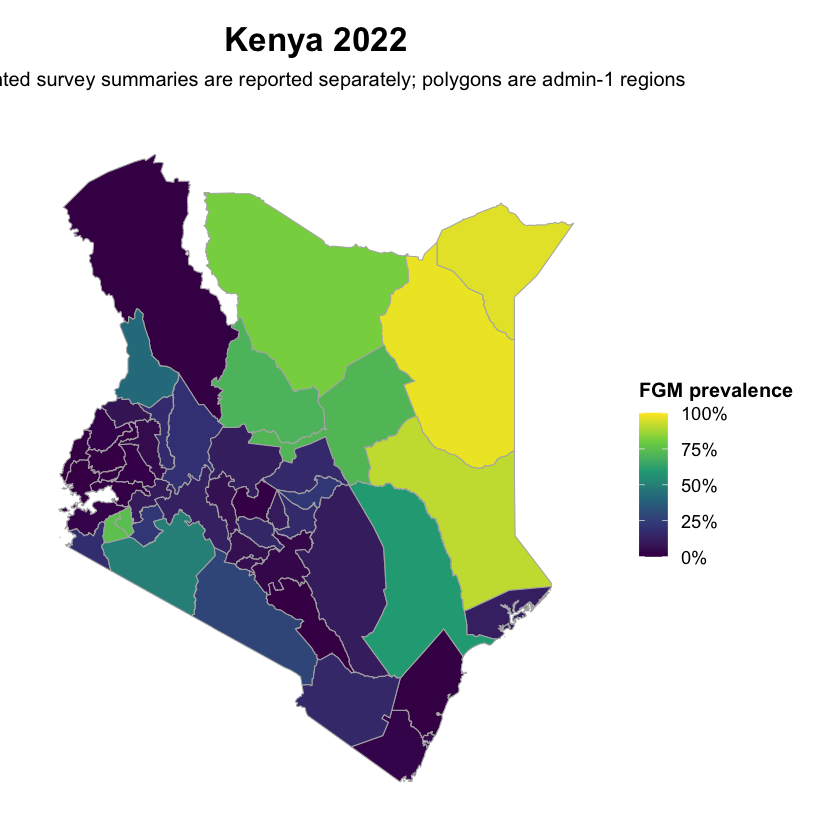

In [39]:
plot_cluster_map(person_by_year[[latest_year]], geo_by_year[[latest_year]], latest_year)

In [40]:
#file.exists(admin1_boundary_path)


In [41]:
save_processed_year <- function(person, geo, year) {
  out_dir <- file.path(processed_country_dir, year)
  dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
  saveRDS(person, file.path(out_dir, "person_level.rds"))
  write_csv(person, file.path(out_dir, "person_level.csv"))
  saveRDS(geo, file.path(out_dir, "cluster_geo.rds"))
  st_write(geo, file.path(out_dir, "cluster_geo.gpkg"), delete_dsn = TRUE, quiet = TRUE)
}

for (yr in names(person_by_year)) {
  save_processed_year(person_by_year[[yr]], geo_by_year[[yr]], yr)
}

list.files(processed_country_dir, recursive = TRUE)

[1] "2022/cluster_geo.gpkg"                            
 [2] "2022/cluster_geo.rds"                             
 [3] "2022/person_level.csv"                            
 [4] "2022/person_level.rds"                            
 [5] "KEN_person_time.csv"                              
 [6] "combined/KEN_attitude.csv"                        
 [7] "combined/KEN_attitude.rds"                        
 [8] "combined/KEN_fgm_events.csv"                      
 [9] "combined/KEN_fgm_events.rds"                      
[10] "prevalence/KEN_prevalence_daughter.csv"           
[11] "prevalence/KEN_prevalence_daughter.rds"           
[12] "prevalence/KEN_prevalence_selected_predictors.rds"
[13] "prevalence/KEN_prevalence_self.csv"               
[14] "prevalence/KEN_prevalence_self.rds"               
[15] "reference/KEN_2022_raw_data_dictionary.csv"

## 11. Combined view across years, and the modeling-ready files

Stacks every harmonized year and looks across them: the national and by-region
prevalence trend as more years accumulate, a prevalence-by-age-group view per year (a
quick proxy for cohort decline without building the full time-to-event structure that
`FGM_Risk_Incidence.ipynb` does), and an overlay map of every year's clusters. With one
year available these are single points rather than trend lines, they start being
genuinely useful once a second year is added back.

In [42]:
person_all <- bind_rows(person_by_year)
daughter_all <- bind_rows(daughter_by_year)
geo_all <- bind_rows(geo_by_year, .id = "survey_year")

# Ethnicity grouping (section 3/section 0's ethnicity_top_n): computed once, across every
# year combined, and applied identically to respondent and daughter records, so the same
# category means the same thing everywhere in fgm_events_all rather than drifting year to
# year or between the two record types.
ethnicity_groups <- person_all |>
  filter(!is.na(ethnicity_raw)) |>
  count(ethnicity_raw, sort = TRUE) |>
  slice_head(n = ethnicity_top_n) |>
  pull(ethnicity_raw)

group_ethnicity <- function(ethnicity_raw) {
  case_when(
    is.na(ethnicity_raw) ~ NA_character_,
    ethnicity_raw %in% ethnicity_groups ~ ethnicity_raw,
    TRUE ~ "other"
  )
}

person_all   <- person_all   |> mutate(ethnicity = group_ethnicity(ethnicity_raw))
daughter_all <- daughter_all |> mutate(ethnicity = group_ethnicity(ethnicity_raw))

cat("ethnicity groups kept (plus \"other\" for everything else):",
    paste(ethnicity_groups, collapse = ", "), "\n")

ethnicity groups kept (plus "other" for everything else): kalenjin, kikuyu, luhya, other, luo, kamba, somali, kisii 


### Write the modeling-ready files

`FGM_Risk_Incidence.ipynb` and `FGM_Attitudinal_Incidence.ipynb` each expect a specific
shape (column names carried over from their original design, kept as-is here so their
downstream modeling code needs no changes): an `id`/`country` column and, for risk
incidence, `fgm_event`/`time`/`birth_cohort`; for attitude, `own_status` and the
individual/community covariates. Both are written once here so neither notebook has to
re-derive them from raw DHS variable codes.

`fgm_events_all` now stacks two kinds of record, distinguished by `record_type`: `self`
(a respondent's own retrospective status, unchanged from before) and `daughter` (one row
per daughter aged 0-14 reconstructed in section 9, inheriting her mother's design
variables). Both feed the same time-to-event model in `FGM_Risk_Incidence.ipynb`,
`record_type` is available there as a covariate to control for any systematic difference
between self-report and a mother reporting on her daughter's behalf.

In [43]:
fgm_events_self <- person_all |>
  filter(!is.na(fgm_event)) |>
  transmute(
    id = resp_id, record_type = "self", survey_type, survey_year, country = country_iso3,
    region, cluster, urban_rural, weight, psu, strata,lat, lon, missing_gps,
    age, birth_year, birth_cohort, ethnicity, fgm_event, time
  )

fgm_events_daughter <- daughter_all |>
  filter(!is.na(fgm_event)) |>
  transmute(
    id = paste0(resp_id, "-d", birth_order), record_type = "daughter",
    survey_type = "DHS", survey_year, country = country_iso3,
    region, cluster, urban_rural, weight, psu, strata,lat, lon, missing_gps,
    age, birth_year, birth_cohort, ethnicity, fgm_event, time
  )

fgm_events_all <- bind_rows(fgm_events_self, fgm_events_daughter)

attitude_all <- person_all |>
  filter(!is.na(supports_continuation)) |>
  transmute(
    id = resp_id, survey_type, survey_year, country = country_iso3,
    region, cluster, urban_rural, weight, psu, strata,lat, lon, missing_gps,
    own_status = fgm_status, education, wealth, religion, ethnicity,
    supports_continuation
  )

combined_dir <- file.path(processed_country_dir, "combined")
dir.create(combined_dir, recursive = TRUE, showWarnings = FALSE)

saveRDS(fgm_events_all, file.path(combined_dir, paste0(country_iso3, "_fgm_events.rds")))
write_csv(fgm_events_all, file.path(combined_dir, paste0(country_iso3, "_fgm_events.csv")))
saveRDS(attitude_all, file.path(combined_dir, paste0(country_iso3, "_attitude.rds")))
write_csv(attitude_all, file.path(combined_dir, paste0(country_iso3, "_attitude.csv")))

cat("fgm_events_all:", nrow(fgm_events_all), "rows (",
    sum(fgm_events_all$record_type == "self"), "self,",
    sum(fgm_events_all$record_type == "daughter"), "daughter)\n")
cat("attitude_all:  ", nrow(attitude_all), "rows,", n_distinct(attitude_all$id), "respondents\n")
cat("written to:", combined_dir, "\n")

fgm_events_all: 31447 rows ( 16902 self, 14545 daughter)
attitude_all:   15890 rows, 15890 respondents
written to: ../02_Data/processed/KEN/combined 


`geom_line()`: Each group consists of only one observation.
i Do you need to adjust the group aesthetic?


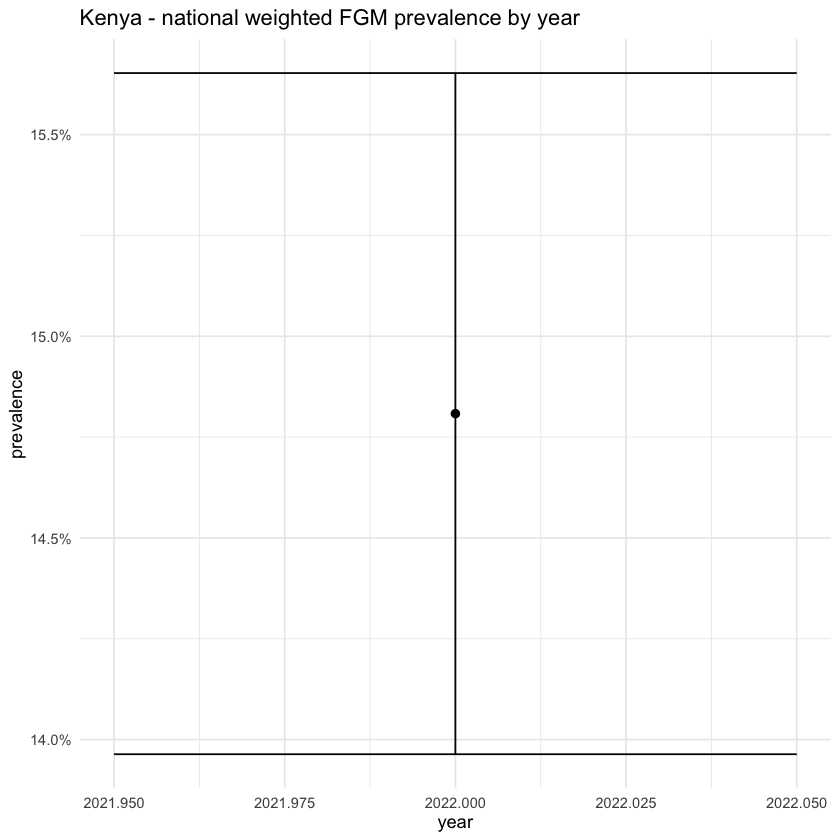

In [44]:
complete_all <- person_all |> filter(!is.na(fgm_status))
des_all <- svydesign(ids = ~psu, strata = ~interaction(survey_year, strata),
                      weights = ~weight, data = complete_all, nest = TRUE)

national_trend <- svyby(~fgm_status, ~survey_year, des_all, svymean) |> as_tibble()

ggplot(national_trend, aes(x = survey_year, y = fgm_status, group = 1)) +
  geom_line(color = "#4C6EF5") +
  geom_point(size = 2) +
  geom_errorbar(aes(ymin = pmax(fgm_status - 1.96 * se, 0), ymax = fgm_status + 1.96 * se),
                width = 0.1) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- national weighted FGM prevalence by year"),
       x = "year", y = "prevalence")

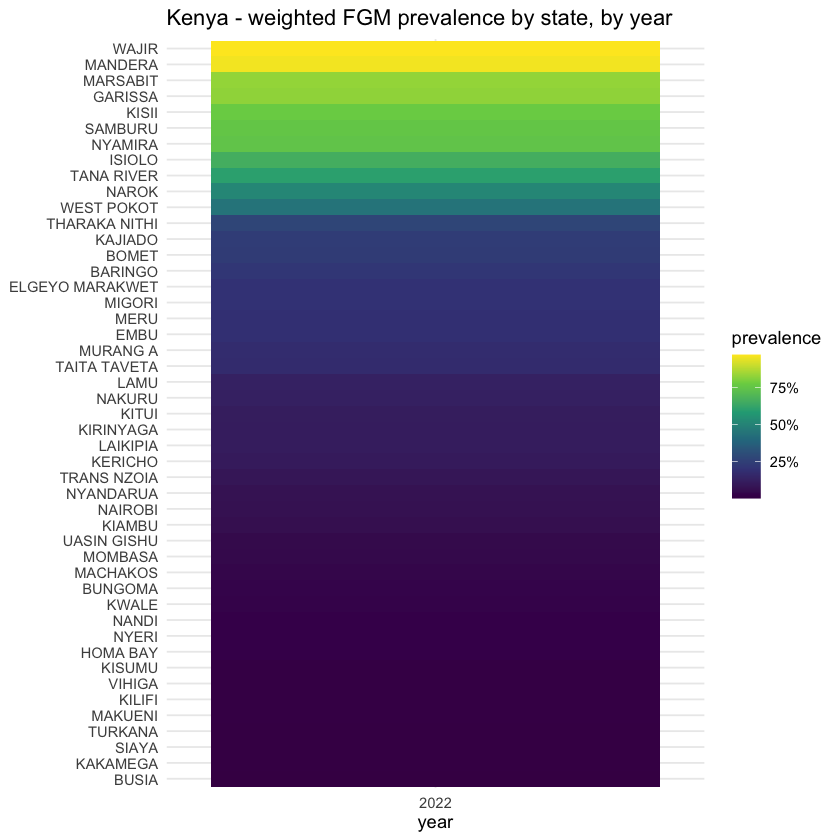

In [45]:
des_all_state <- svydesign(ids = ~psu, strata = ~interaction(survey_year, strata),
                            weights = ~weight,
                            data = complete_all |> filter(!is.na(region)), nest = TRUE)

state_trend <- svyby(~fgm_status, ~survey_year + region, des_all_state, svymean) |>
  as_tibble()

# A state per line would be unreadable at 37 categories, a heatmap keeps every state
# readable and makes years where prevalence rose or fell easy to spot by eye.
state_order <- state_trend |>
  group_by(region) |>
  summarise(avg = mean(fgm_status), .groups = "drop") |>
  arrange(avg) |>
  pull(region)

ggplot(state_trend |> mutate(region = factor(region, levels = state_order)),
       aes(x = factor(survey_year), y = region, fill = fgm_status)) +
  geom_tile() +
  scale_fill_viridis_c(labels = scales::percent, name = "prevalence") +
  labs(title = paste(country_name, "- weighted FGM prevalence by state, by year"),
       x = "year", y = NULL)

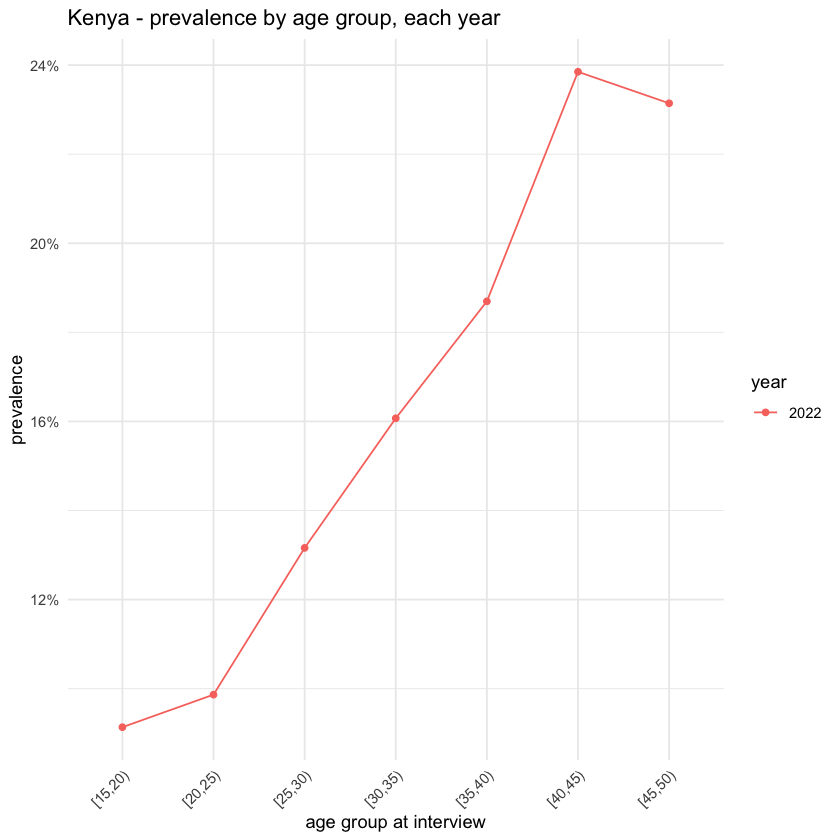

In [46]:
age_group_trend <- person_all |>
  mutate(age_group = cut(age, breaks = seq(15, 50, by = 5), right = FALSE)) |>
  filter(!is.na(age_group)) |>
  group_by(survey_year, age_group) |>
  summarise(prev = weighted.mean(fgm_status, weight, na.rm = TRUE), .groups = "drop")

ggplot(age_group_trend, aes(x = age_group, y = prev, group = survey_year, color = factor(survey_year))) +
  geom_line() +
  geom_point() +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- prevalence by age group, each year"),
       x = "age group at interview", y = "prevalence", color = "year") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

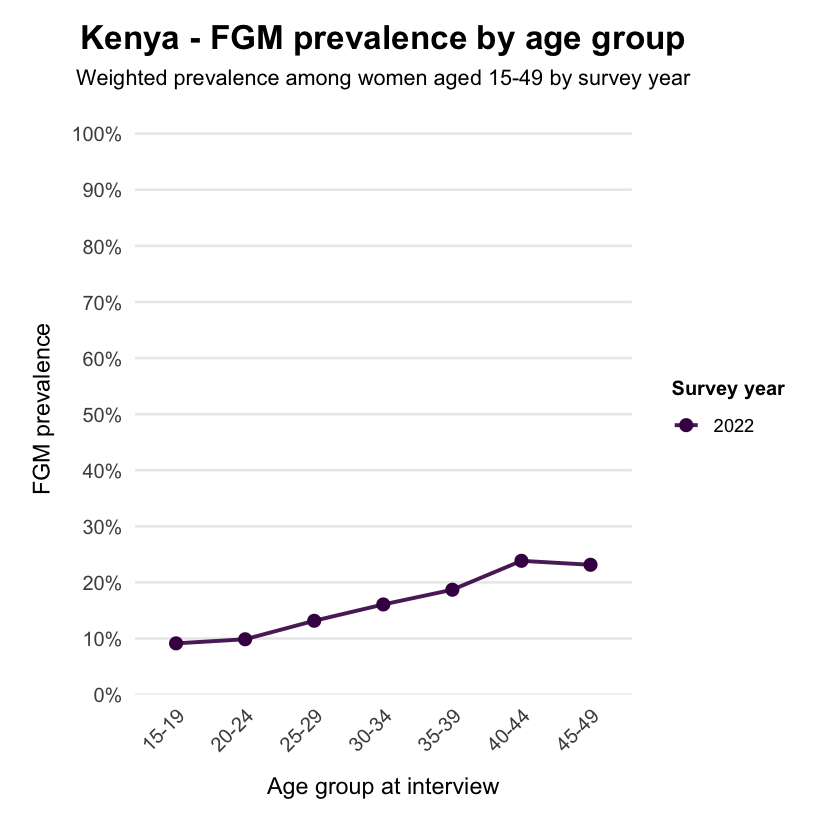

In [47]:
# ---------------------------------------------------------
# FGM prevalence by age group and survey year
# ---------------------------------------------------------

age_group_trend <- person_all |>

  mutate(
    age_group = cut(
      age,
      breaks = seq(15, 50, by = 5),
      right = FALSE,
      include.lowest = TRUE,
      labels = c(
        "15-19",
        "20-24",
        "25-29",
        "30-34",
        "35-39",
        "40-44",
        "45-49"
      )
    )
  ) |>

  filter(
    !is.na(age_group),
    !is.na(fgm_status),
    !is.na(weight),
    weight > 0
  ) |>

  group_by(
    survey_year,
    age_group
  ) |>

  summarise(
    prevalence = weighted.mean(
      fgm_status,
      w = weight,
      na.rm = TRUE
    ),
    n = n(),
    .groups = "drop"
  ) |>

  mutate(
    survey_year = factor(survey_year),

    age_group = factor(
      age_group,
      levels = c(
        "15-19",
        "20-24",
        "25-29",
        "30-34",
        "35-39",
        "40-44",
        "45-49"
      )
    )
  )


# ---------------------------------------------------------
# Plot: FGM prevalence by age group and survey year
# ---------------------------------------------------------

ggplot(
  age_group_trend,
  aes(
    x = age_group,
    y = prevalence,
    group = survey_year,
    color = survey_year
  )
) +

  geom_line(
    linewidth = 1.1,
    alpha = 0.9
  ) +

  geom_point(
    size = 3
  ) +

  scale_x_discrete(
    drop = FALSE
  ) +

  scale_y_continuous(
    labels = scales::percent_format(accuracy = 1),
    limits = c(0, 1),
    breaks = seq(0, 1, by = 0.1),
    expand = expansion(mult = c(0, 0.02))
  ) +

  scale_color_viridis_d(
    option = "D",
    end = 0.90,
    name = "Survey year"
  ) +

  labs(
    title = paste(country_name, "- FGM prevalence by age group"),
    subtitle = "Weighted prevalence among women aged 15-49 by survey year",
    x = "Age group at interview",
    y = "FGM prevalence"
  ) +

  theme_minimal(base_size = 16) +

  theme(
    plot.title = element_text(
      face = "bold",
      size = 20,
      hjust = 0.5
    ),

    plot.subtitle = element_text(
      size = 13,
      hjust = 0.5,
      margin = margin(b = 20)
    ),

    axis.text.x = element_text(
      angle = 45,
      hjust = 1,
      vjust = 1,
      size = 12
    ),

    axis.text.y = element_text(
      size = 12
    ),

    axis.title.x = element_text(
      size = 14,
      margin = margin(t = 12)
    ),

    axis.title.y = element_text(
      size = 14,
      margin = margin(r = 10)
    ),

    legend.title = element_text(
      face = "bold",
      size = 12
    ),

    legend.text = element_text(
      size = 11
    ),

    panel.grid.major.x = element_blank(),
    panel.grid.minor = element_blank(),

    plot.margin = margin(
      t = 15,
      r = 25,
      b = 25,
      l = 20
    )
  )

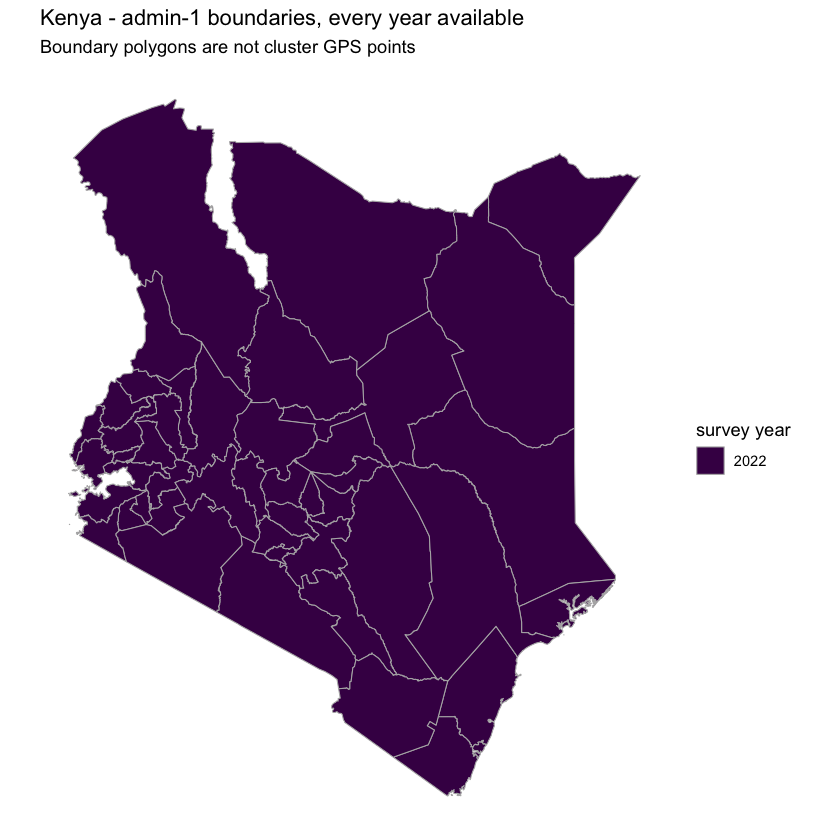

In [48]:
map_all <- geo_all

ggplot(map_all) +
  geom_sf(aes(fill = survey_year), color = "grey70", linewidth = 0.3) +
  scale_fill_viridis_d(name = "survey year") +
  labs(
    title = paste(country_name, "- admin-1 boundaries, every year available"),
    subtitle = "Boundary polygons are not cluster GPS points"
  ) +
  theme_minimal() +
  theme(axis.text = element_blank(), axis.title = element_blank(), panel.grid = element_blank())

## 12. Notes for the next country / next year

- **Kenya geography**: the supplied 2022 shapefile is an admin-1 polygon layer with 47 counties. Its metadata states that `REGCODE` aligns to survey variable `hv024`; the individual recode uses the corresponding `v024`. This notebook joins those numeric codes and does not infer cluster GPS.
- **Adding a Kenya survey year**: place the IR `.dta` and admin-1 `.shp` under a new `02_Data/raw/<year>/` folder. Discovery will pick them up automatically.
- **Modeling outputs**: the modeling notebooks read `02_Data/processed/KEN/combined/KEN_fgm_events.rds` and `KEN_attitude.rds` after this notebook has run.
- **Daughter roster**: the Kenya file contains the expected `gidx_*`, `g121_*`, `g122_*`, `bidx_*`, and `b8_*` fields, so daughter records can be reconstructed and should be checked in the printed count.
- **Boundary validation**: the boundary package itself supplies the survey-aligned admin-1 polygons. A separate authoritative polygon layer is not required for this code-based join, but any future source should be checked for matching region codes before use.